**Prévision de consommation électrique**

**Problématique** *Peut-on prévoir la consommation électrique française à J+1 avec précision ?<br> Quel gain apportent la météo et le calendrier par rapport à une baseline simple ?<br> Le modèle peut-il approcher ou battre la prévision publiée par RTE ?*

**Les sources utilisées :**<br>
*éCO2mix national temps réel*<br> 
*éCO2mix régionales consolidées et définitives*<br>
*éCO2mix régionales temps réel*<br>
*Open-Meteo Historical Weather API*<br>
*Calendrier scolaire*<br>
*Jours fériés en France*<br>

**Etape 1 : Installations des dépendances nécessaires**

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import holidays
from datetime import datetime, timedelta

# Préparation des données et Machine Learning
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Modèle de gradient boosting
import lightgbm as lgb

# Explicabilité du modèle
import shap

# Gestion des avertissements
import warnings
warnings.filterwarnings("ignore")

# Configuration de l'affichage
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 50)
pd.set_option("display.width", 120)

from pathlib import Path

print("Imports effectués avec succès.")


Imports effectués avec succès.


**Import et nettoyage des données**

In [4]:
DATA_PATH = Path('/Users/matteolouet/Desktop/projets perso/Projet ML RTE /eco2mix-regional-cons-def.csv')

# Vérifier que le fichier existe
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Fichier introuvable : {DATA_PATH.resolve()}\n"
        "Vérifie son emplacement et son nom."
    )

# Charger les données
df = pd.read_csv(DATA_PATH, sep=";", low_memory=False)

print("Dimensions du jeu de données :", df.shape)
display(df.head())

Dimensions du jeu de données : (2874816, 32)


,Code INSEE région,Région,Nature,Date,Heure,Date - Heure,Consommation (MW),Thermique (MW),Nucléaire (MW),Eolien (MW),Solaire (MW),Hydraulique (MW),Pompage (MW),Bioénergies (MW),Ech. physiques (MW),Stockage batterie,Déstockage batterie,Eolien terrestre,Eolien offshore,TCO Thermique (%),TCH Thermique (%),TCO Nucléaire (%),TCH Nucléaire (%),TCO Eolien (%),TCH Eolien (%),TCO Solaire (%),TCH Solaire (%),TCO Hydraulique (%),TCH Hydraulique (%),TCO Bioénergies (%),TCH Bioénergies (%),Column 30
0,76,Occitanie,Données consolidées,2026-08-31,23:30,2026-08-31T21:30:00+00:00,3805.0,1.0,1257.0,376,2.0,1167.0,0.0,68.0,934.0,0.0,0.0,320.0,56.0,0.03,0.38,33.04,47.98,9.88,20.43,0.05,0.04,30.67,21.76,1.79,38.20,NaN
1,52,Pays de la Loire,Données consolidées,2026-08-31,23:30,2026-08-31T21:30:00+00:00,2457.0,0.0,0.0,215,0.0,0.0,0.0,52.0,2194.0,0.0,0.0,69.0,146.0,0.00,0.00,0.00,NaN,8.75,8.75,0.00,0.00,0.00,0.00,2.12,57.14,NaN
2,75,Nouvelle-Aquitaine,Données consolidées,2026-08-31,23:30,2026-08-31T21:30:00+00:00,3994.0,14.0,4145.0,209,0.0,78.0,0.0,196.0,-646.0,0.0,0.0,209.0,0.0,0.35,2.56,103.78,62.52,5.23,9.34,0.00,0.00,1.95,3.49,4.91,56.98,NaN
3,84,Auvergne-Rhône-Alpes,Données consolidées,2026-08-31,23:30,2026-08-31T21:30:00+00:00,6204.0,395.0,10669.0,100,0.0,2026.0,-4.0,103.0,-7084.0,0.0,0.0,100.0,0.0,6.37,41.40,171.97,78.62,1.61,12.53,0.00,0.00,32.66,17.69,1.66,54.79,NaN
4,44,Grand Est,Données consolidées,2026-08-31,23:30,2026-08-31T21:30:00+00:00,4078.0,907.0,4666.0,425,0.0,484.0,0.0,166.0,-2546.0,0.0,0.0,425.0,0.0,22.24,29.45,114.42,43.12,10.42,8.18,0.00,0.00,11.87,21.03,4.07,61.71,NaN


In [5]:
# Types des colonnes et valeurs non nulles
df.info()

# Noms des colonnes
print("\nColonnes disponibles :")
print(df.columns.tolist())

# Pourcentage de valeurs manquantes
display(
    (df.isna().mean() * 100)
    .sort_values(ascending=False)
    .round(2)
    .to_frame(name="Pourcentage de valeurs manquantes")
    .head(20)
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2874816 entries, 0 to 2874815
Data columns (total 32 columns):
 #   Column               Dtype  
---  ------               -----  
 0   Code INSEE région    int64  
 1   Région               object 
 2   Nature               object 
 3   Date                 object 
 4   Heure                object 
 5   Date - Heure         object 
 6   Consommation (MW)    float64
 7   Thermique (MW)       float64
 8   Nucléaire (MW)       float64
 9   Eolien (MW)          object 
 10  Solaire (MW)         float64
 11  Hydraulique (MW)     float64
 12  Pompage (MW)         float64
 13  Bioénergies (MW)     float64
 14  Ech. physiques (MW)  float64
 15  Stockage batterie    float64
 16  Déstockage batterie  float64
 17  Eolien terrestre     float64
 18  Eolien offshore      float64
 19  TCO Thermique (%)    float64
 20  TCH Thermique (%)    float64
 21  TCO Nucléaire (%)    float64
 22  TCH Nucléaire (%)    float64
 23  TCO Eolien (%)       float64
 24

,Pourcentage de valeurs manquantes
Column 30,100.00
TCH Nucléaire (%),71.54
Stockage batterie,58.55
Eolien offshore,58.55
Eolien terrestre,58.55
Déstockage batterie,58.55
TCO Nucléaire (%),54.27
TCO Thermique (%),51.21
TCO Bioénergies (%),51.21
TCO Hydraulique (%),51.21


*Afin d'éviter les chargements inutiles on ne va garder que ce qui sera utile à la prévision*

In [6]:
# Sélection des colonnes utiles pour la prévision de consommation

colonnes_utiles = [
    "Code INSEE région",
    "Région",
    "Date",
    "Heure",
    "Date - Heure",
    "Consommation (MW)"
]

df_travail = df[colonnes_utiles].copy()

# Conversion des dates
df_travail["Date - Heure"] = pd.to_datetime(
    df_travail["Date - Heure"],
    errors="coerce",
    utc=True
)

df_travail["Date"] = pd.to_datetime(
    df_travail["Date"],
    errors="coerce"
)

# Vérification
print("Dimensions du DataFrame de travail :", df_travail.shape)
print("\nTypes des colonnes :")
print(df_travail.dtypes)

display(df_travail.head())


Dimensions du DataFrame de travail : (2874816, 6)

Types des colonnes :
Code INSEE région                  int64
Région                            object
Date                      datetime64[ns]
Heure                             object
Date - Heure         datetime64[ns, UTC]
Consommation (MW)                float64
dtype: object


,Code INSEE région,Région,Date,Heure,Date - Heure,Consommation (MW)
0,76,Occitanie,2026-08-31,23:30,2026-08-31 21:30:00+00:00,3805.0
1,52,Pays de la Loire,2026-08-31,23:30,2026-08-31 21:30:00+00:00,2457.0
2,75,Nouvelle-Aquitaine,2026-08-31,23:30,2026-08-31 21:30:00+00:00,3994.0
3,84,Auvergne-Rhône-Alpes,2026-08-31,23:30,2026-08-31 21:30:00+00:00,6204.0
4,44,Grand Est,2026-08-31,23:30,2026-08-31 21:30:00+00:00,4078.0


*Vérification des couvertures temporelles et géographiques*

In [7]:

# Vérifier la période couverte
print("Date minimale :", df_travail["Date - Heure"].min())
print("Date maximale :", df_travail["Date - Heure"].max())

# Nombre de régions
print("\nNombre de régions distinctes :",
      df_travail["Région"].nunique())

print("\nRégions présentes :")
display(
    df_travail["Région"]
    .value_counts()
    .rename_axis("Région")
    .to_frame(name="Nombre de lignes")
)

# Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
display(df_travail.isna().sum().to_frame(name="Valeurs manquantes"))


Date minimale : 2012-12-31 23:00:00+00:00
Date maximale : 2026-08-31 21:30:00+00:00

Nombre de régions distinctes : 12

Régions présentes :


,Nombre de lignes
Région,
Occitanie,239568
Pays de la Loire,239568
Nouvelle-Aquitaine,239568
Auvergne-Rhône-Alpes,239568
Grand Est,239568
Bourgogne-Franche-Comté,239568
Normandie,239568
Bretagne,239568
Hauts-de-France,239568



Valeurs manquantes :


,Valeurs manquantes
Code INSEE région,0
Région,0
Date,0
Heure,0
Date - Heure,0
Consommation (MW),24


*Recherche de doublon*

In [8]:

# Doublons sur le couple région / date-heure
nb_doublons = df_travail.duplicated(
    subset=["Région", "Date - Heure"]
).sum()

print("Nombre de doublons région / date-heure :", nb_doublons)

# Examiner les éventuels doublons
doublons = df_travail[
    df_travail.duplicated(
        subset=["Région", "Date - Heure"],
        keep=False
    )
].sort_values(["Région", "Date - Heure"])

display(doublons.head(10))


Nombre de doublons région / date-heure : 336


,Code INSEE région,Région,Date,Heure,Date - Heure,Consommation (MW)
2823493,84,Auvergne-Rhône-Alpes,2013-03-31,02:00,2013-03-31 01:00:00+00:00,7809.0
2823494,84,Auvergne-Rhône-Alpes,2013-03-31,03:00,2013-03-31 01:00:00+00:00,7809.0
2823472,84,Auvergne-Rhône-Alpes,2013-03-31,03:30,2013-03-31 01:30:00+00:00,7988.0
2823478,84,Auvergne-Rhône-Alpes,2013-03-31,02:30,2013-03-31 01:30:00+00:00,7796.0
2613826,84,Auvergne-Rhône-Alpes,2014-03-30,02:00,2014-03-30 01:00:00+00:00,6537.0
2613834,84,Auvergne-Rhône-Alpes,2014-03-30,03:00,2014-03-30 01:00:00+00:00,6537.0
2613794,84,Auvergne-Rhône-Alpes,2014-03-30,02:30,2014-03-30 01:30:00+00:00,6556.0
2613810,84,Auvergne-Rhône-Alpes,2014-03-30,03:30,2014-03-30 01:30:00+00:00,6686.0
2404170,84,Auvergne-Rhône-Alpes,2015-03-29,02:00,2015-03-29 01:00:00+00:00,7248.0
2404173,84,Auvergne-Rhône-Alpes,2015-03-29,03:00,2015-03-29 01:00:00+00:00,7248.0


*Recherche de la fréquence*

In [9]:

# Nombre d'instants distincts
instants = (
    df_travail["Date - Heure"]
    .dropna()
    .drop_duplicates()
    .sort_values()
)

ecarts = instants.diff().dropna()

print("Nombre d'instants distincts :", len(instants))
print("\nÉcarts temporels les plus fréquents :")
display(
    ecarts.value_counts().head(10).to_frame(name="Occurrences")
)


Nombre d'instants distincts : 239540

Écarts temporels les plus fréquents :


,Occurrences
Date - Heure,
0 days 00:30:00,239526
0 days 01:30:00,13


*On constate que la répartition entre régions est équilibrée, les valeurs manquantes sont négligeables par rapport à la taille de l'échantillon,pour ce qui est des doublons ils sont en grande partie dus aux changements d'heure. Enfin, on voit que la fréquence de relevé est majoritairement de 30 minutes. <br>Il faut maintenant analyser plus en détail les doublons/valeurs manquantes.*

In [10]:
# 1. Examiner les doublons apparents
doublons = df_travail[
    df_travail.duplicated(
        subset=["Région", "Date - Heure"],
        keep=False
    )
].sort_values(["Région", "Date - Heure"])

print("Nombre de lignes concernées :", len(doublons))

display(
    doublons[
        [
            "Région",
            "Date",
            "Heure",
            "Date - Heure",
            "Consommation (MW)"
        ]
    ].head(20)
)

# 2. Examiner les valeurs manquantes de consommation
manquantes = df_travail[
    df_travail["Consommation (MW)"].isna()
]

print("\nNombre de consommations manquantes :", len(manquantes))
display(manquantes.head(20))

# 3. Vérifier si les doublons ont des consommations identiques
comparaison_doublons = (
    doublons.groupby(["Région", "Date - Heure"])
    ["Consommation (MW)"]
    .agg(["count", "nunique", "min", "max"])
)

print("\nRésumé des doublons :")
display(comparaison_doublons.head(20))

Nombre de lignes concernées : 672


,Région,Date,Heure,Date - Heure,Consommation (MW)
2823493,Auvergne-Rhône-Alpes,2013-03-31,02:00,2013-03-31 01:00:00+00:00,7809.0
2823494,Auvergne-Rhône-Alpes,2013-03-31,03:00,2013-03-31 01:00:00+00:00,7809.0
2823472,Auvergne-Rhône-Alpes,2013-03-31,03:30,2013-03-31 01:30:00+00:00,7988.0
2823478,Auvergne-Rhône-Alpes,2013-03-31,02:30,2013-03-31 01:30:00+00:00,7796.0
2613826,Auvergne-Rhône-Alpes,2014-03-30,02:00,2014-03-30 01:00:00+00:00,6537.0
2613834,Auvergne-Rhône-Alpes,2014-03-30,03:00,2014-03-30 01:00:00+00:00,6537.0
2613794,Auvergne-Rhône-Alpes,2014-03-30,02:30,2014-03-30 01:30:00+00:00,6556.0
2613810,Auvergne-Rhône-Alpes,2014-03-30,03:30,2014-03-30 01:30:00+00:00,6686.0
2404170,Auvergne-Rhône-Alpes,2015-03-29,02:00,2015-03-29 01:00:00+00:00,7248.0
2404173,Auvergne-Rhône-Alpes,2015-03-29,03:00,2015-03-29 01:00:00+00:00,7248.0



Nombre de consommations manquantes : 24


,Code INSEE région,Région,Date,Heure,Date - Heure,Consommation (MW)
139956,11,Île-de-France,2026-01-01,00:00,2025-12-31 23:00:00+00:00,NaN
139957,24,Centre-Val de Loire,2026-01-01,00:00,2025-12-31 23:00:00+00:00,NaN
139958,93,Provence-Alpes-Côte d'Azur,2026-01-01,00:00,2025-12-31 23:00:00+00:00,NaN
139959,76,Occitanie,2026-01-01,00:00,2025-12-31 23:00:00+00:00,NaN
139960,28,Normandie,2026-01-01,00:00,2025-12-31 23:00:00+00:00,NaN
139961,32,Hauts-de-France,2026-01-01,00:00,2025-12-31 23:00:00+00:00,NaN
139962,44,Grand Est,2026-01-01,00:00,2025-12-31 23:00:00+00:00,NaN
139963,27,Bourgogne-Franche-Comté,2026-01-01,00:00,2025-12-31 23:00:00+00:00,NaN
139964,75,Nouvelle-Aquitaine,2026-01-01,00:00,2025-12-31 23:00:00+00:00,NaN
139965,53,Bretagne,2026-01-01,00:00,2025-12-31 23:00:00+00:00,NaN



Résumé des doublons :


count  nunique     min     max
Région               Date - Heure                                             
Auvergne-Rhône-Alpes 2013-03-31 01:00:00+00:00      2        1  7809.0  7809.0
                     2013-03-31 01:30:00+00:00      2        2  7796.0  7988.0
                     2014-03-30 01:00:00+00:00      2        1  6537.0  6537.0
                     2014-03-30 01:30:00+00:00      2        2  6556.0  6686.0
                     2015-03-29 01:00:00+00:00      2        1  7248.0  7248.0
                     2015-03-29 01:30:00+00:00      2        2  7288.0  7381.0
                     2016-03-27 01:00:00+00:00      2        1  6970.0  6970.0
                     2016-03-27 01:30:00+00:00      2        2  6958.0  7090.0
                     2017-03-26 01:00:00+00:00      2        1  7069.0  7069.0
                     2017-03-26 01:30:00+00:00      2        2  7100.0  7236.0
                     2018-03-25 01:00:00+00:00      2        1  7704.0  7704.0
                     2018-03-25 01:30:00+00:00      2        2  7711.0  7885.0
                     2019-03-31 01:00:00+00:00      2        1  6515.0  6515.0
                     2019-03-31 01:30:00+00:00      2        2  6501.0  6625.0
                     2020-03-29 01:00:00+00:00      2        1  5854.0  5854.0
                     2020-03-29 01:30:00+00:00      2        2  5844.0  5988.0
                     2021-03-28 01:00:00+00:00      2        1  7017.0  7017.0
                     2021-03-28 01:30:00+00:00      2        1  7216.0  7216.0
                     2022-03-27 01:00:00+00:00      2        1  6397.0  6397.0
                     2022-03-27 01:30:00+00:00      2        1  6555.0  6555.0

*Le test confirme que l'heure peut jouer, on va donc convertir en UTC pour voir ce qu'il en est*

In [11]:
# Examiner les lignes du changement d'heure de mars 2013
masque = (
    (df_travail["Date"] == "2013-03-31")
    & (df_travail["Région"] == "Auvergne-Rhône-Alpes")
)

display(
    df_travail.loc[
        masque,
        ["Région", "Date", "Heure", "Date - Heure", "Consommation (MW)"]
    ].sort_values("Date - Heure")
)

,Région,Date,Heure,Date - Heure,Consommation (MW)
2823540,Auvergne-Rhône-Alpes,2013-03-31,00:00,2013-03-30 23:00:00+00:00,8249.0
2823531,Auvergne-Rhône-Alpes,2013-03-31,00:30,2013-03-30 23:30:00+00:00,8050.0
2823526,Auvergne-Rhône-Alpes,2013-03-31,01:00,2013-03-31 00:00:00+00:00,7799.0
2823507,Auvergne-Rhône-Alpes,2013-03-31,01:30,2013-03-31 00:30:00+00:00,7796.0
2823494,Auvergne-Rhône-Alpes,2013-03-31,03:00,2013-03-31 01:00:00+00:00,7809.0
2823493,Auvergne-Rhône-Alpes,2013-03-31,02:00,2013-03-31 01:00:00+00:00,7809.0
2823478,Auvergne-Rhône-Alpes,2013-03-31,02:30,2013-03-31 01:30:00+00:00,7796.0
2823472,Auvergne-Rhône-Alpes,2013-03-31,03:30,2013-03-31 01:30:00+00:00,7988.0
2823449,Auvergne-Rhône-Alpes,2013-03-31,04:00,2013-03-31 02:00:00+00:00,7696.0
2823440,Auvergne-Rhône-Alpes,2013-03-31,04:30,2013-03-31 02:30:00+00:00,7563.0


In [12]:
# Vérifier si les lignes sont identiques sur toutes les colonnes utiles
nb_doublons_exacts = df_travail.duplicated().sum()

print("Nombre de lignes identiques sur toutes les colonnes utiles :",
      nb_doublons_exacts)

# Vérifier les valeurs de consommation répétées lors des doublons temporels
print("\nNombre de groupes temporels ayant plusieurs consommations distinctes :",
      (comparaison_doublons["nunique"] > 1).sum())

Nombre de lignes identiques sur toutes les colonnes utiles : 0

Nombre de groupes temporels ayant plusieurs consommations distinctes : 121


*Ces résultats confirment que les doublons temporels ne sont pas de simples copies exactes : 121 groupes contiennent plusieurs valeurs de consommation distinctes. Nous ne devons donc pas supprimer arbitrairement les lignes.
Le point à corriger est la gestion des heures : la colonne Date - Heure est en UTC, tandis que Date et Heure représentent les valeurs locales du fichier. Nous allons examiner la structure temporelle avant de choisir la méthode d'agrégation*

In [13]:
# Examiner les timestamps dupliqués entre régions
compte_par_instant = (
    df_travail.groupby("Date - Heure")["Région"]
    .nunique()
)

print("Nombre d'instants :", len(compte_par_instant))
print("\nNombre d'instants avec moins de 12 régions :",
      (compte_par_instant < 12).sum())

print("\nRépartition du nombre de régions par instant :")
display(compte_par_instant.value_counts().sort_index())

# Examiner les lignes autour du changement d'heure de mars 2013
masque = (
    (df_travail["Date"] == "2013-03-31")
    & (df_travail["Région"] == "Auvergne-Rhône-Alpes")
)

display(
    df_travail.loc[
        masque,
        ["Date", "Heure", "Date - Heure", "Consommation (MW)"]
    ].sort_values(["Date", "Heure"])
)

Nombre d'instants : 239540

Nombre d'instants avec moins de 12 régions : 0

Répartition du nombre de régions par instant :


Région
12    239540
Name: count, dtype: int64

,Date,Heure,Date - Heure,Consommation (MW)
2823540,2013-03-31,00:00,2013-03-30 23:00:00+00:00,8249.0
2823531,2013-03-31,00:30,2013-03-30 23:30:00+00:00,8050.0
2823526,2013-03-31,01:00,2013-03-31 00:00:00+00:00,7799.0
2823507,2013-03-31,01:30,2013-03-31 00:30:00+00:00,7796.0
2823493,2013-03-31,02:00,2013-03-31 01:00:00+00:00,7809.0
2823478,2013-03-31,02:30,2013-03-31 01:30:00+00:00,7796.0
2823494,2013-03-31,03:00,2013-03-31 01:00:00+00:00,7809.0
2823472,2013-03-31,03:30,2013-03-31 01:30:00+00:00,7988.0
2823449,2013-03-31,04:00,2013-03-31 02:00:00+00:00,7696.0
2823440,2013-03-31,04:30,2013-03-31 02:30:00+00:00,7563.0


*chacun des 239 540 instants distincts contient bien les 12 régions. Nous pouvons donc construire une série nationale en sommant les consommations régionales par timestamp.*

*chacun des 239 540 instants distincts contient bien les 12 régions. Nous pouvons donc construire une série nationale en sommant les consommations régionales par timestamp.
Il reste une précaution : certains timestamps ont plusieurs lignes pour une même région. Pour éviter de compter deux fois certaines consommations, nous allons d'abord identifier les instants concernés, puis construire une série provisoire en agrégeant les données. Nous conserverons les valeurs manquantes comme telles si une consommation régionale manque*

In [14]:

# Nombre de lignes par région et par instant
comptage = (
    df_travail.groupby(["Date - Heure", "Région"])
    .size()
)

print("Nombre de couples région / instant avec plusieurs lignes :",
      (comptage > 1).sum())

# Convertir la consommation en numérique
df_travail["Consommation (MW)"] = pd.to_numeric(
    df_travail["Consommation (MW)"],
    errors="coerce"
)

# Agrégation provisoire : une somme n'est calculée que si les 12 régions
# ont chacune une seule valeur non manquante à cet instant.
nb_lignes = (
    df_travail.groupby("Date - Heure")["Région"]
    .size()
)

nb_regions = (
    df_travail.groupby("Date - Heure")["Région"]
    .nunique()
)

nb_valeurs = (
    df_travail.groupby("Date - Heure")["Consommation (MW)"]
    .count()
)

somme_regions = (
    df_travail.groupby("Date - Heure")["Consommation (MW)"]
    .sum(min_count=12)
)

df_national = pd.DataFrame({
    "nb_lignes": nb_lignes,
    "nb_regions": nb_regions,
    "nb_valeurs": nb_valeurs,
    "Consommation (MW)": somme_regions
})

# Ne conserver comme valides que les instants ayant exactement
# 12 lignes, 12 régions et 12 consommations disponibles
df_national.loc[
    (df_national["nb_lignes"] != 12)
    | (df_national["nb_regions"] != 12)
    | (df_national["nb_valeurs"] != 12),
    "Consommation (MW)"
] = np.nan

print("Dimensions de la série nationale :", df_national.shape)
print("Consommations nationales manquantes :",
      df_national["Consommation (MW)"].isna().sum())

display(df_national.head())

Nombre de couples région / instant avec plusieurs lignes : 336
Dimensions de la série nationale : (239540, 4)
Consommations nationales manquantes : 30


,nb_lignes,nb_regions,nb_valeurs,Consommation (MW)
Date - Heure,,,,
2012-12-31 23:00:00+00:00,12,12,0,NaN
2012-12-31 23:30:00+00:00,12,12,12,59662.0
2013-01-01 00:00:00+00:00,12,12,12,57866.0
2013-01-01 00:30:00+00:00,12,12,12,57747.0
2013-01-01 01:00:00+00:00,12,12,12,57234.0


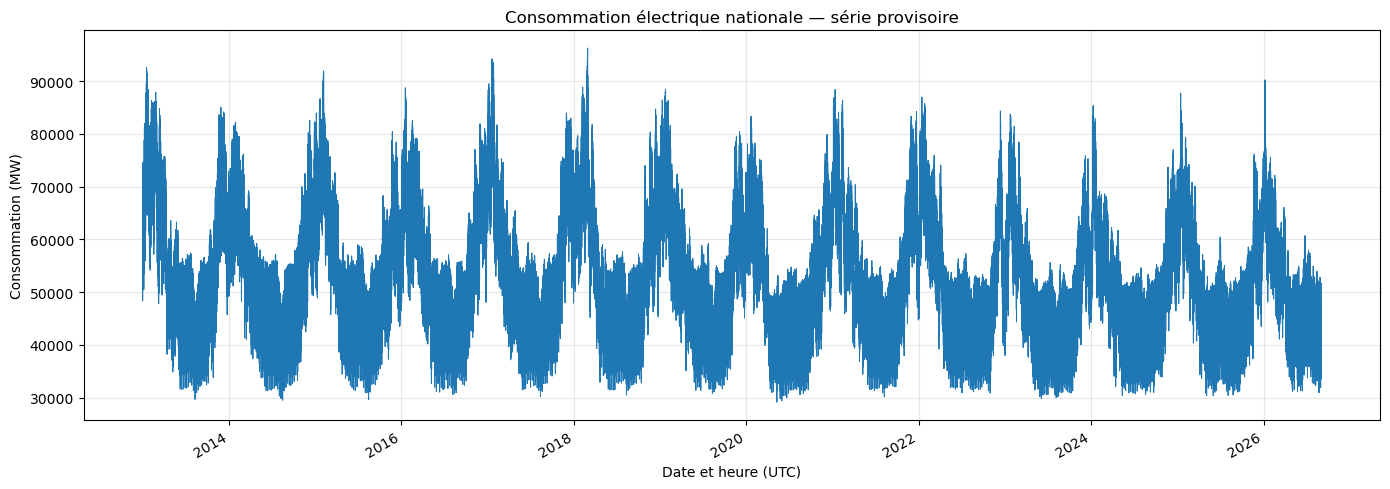

In [15]:

plt.figure(figsize=(14, 5))

df_national["Consommation (MW)"].plot(
    linewidth=0.7,
    title="Consommation électrique nationale — série provisoire"
)

plt.xlabel("Date et heure (UTC)")
plt.ylabel("Consommation (MW)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


*Maintenant que nous avons vérifié, nous devons examiner les timestamps concernés et vérifier si les doublons correspondent à des consommations identiques ou contradictoires. Ensuite, nous pourrons fiabiliser la série nationale.*

In [16]:
# Identifier les couples région / instant dupliqués
comptage = (
    df_travail.groupby(["Date - Heure", "Région"])
    .size()
)

couples_dupliques = comptage[comptage > 1]

print("Couples région / instant dupliqués :", len(couples_dupliques))

# Examiner les valeurs associées aux doublons
index_dupliques = couples_dupliques.index

df_doublons = (
    df_travail.set_index(["Date - Heure", "Région"])
    .loc[index_dupliques]
    .reset_index()
    .sort_values(["Date - Heure", "Région"])
)

display(df_doublons.head(30))

# Résumer les doublons selon leur nombre de valeurs distinctes
resume_doublons = (
    df_doublons
    .groupby(["Date - Heure", "Région"])["Consommation (MW)"]
    .agg(["count", "nunique", "min", "max"])
)

print("\nRépartition des groupes selon le nombre de valeurs distinctes :")
display(resume_doublons["nunique"].value_counts().sort_index())

Couples région / instant dupliqués : 336


,Date - Heure,Région,Code INSEE région,Date,Heure,Consommation (MW)
0,2013-03-31 01:00:00+00:00,Auvergne-Rhône-Alpes,84,2013-03-31,02:00,7809.0
1,2013-03-31 01:00:00+00:00,Auvergne-Rhône-Alpes,84,2013-03-31,03:00,7809.0
2,2013-03-31 01:00:00+00:00,Bourgogne-Franche-Comté,27,2013-03-31,02:00,2588.0
3,2013-03-31 01:00:00+00:00,Bourgogne-Franche-Comté,27,2013-03-31,03:00,2588.0
4,2013-03-31 01:00:00+00:00,Bretagne,53,2013-03-31,03:00,3642.0
5,2013-03-31 01:00:00+00:00,Bretagne,53,2013-03-31,02:00,3642.0
6,2013-03-31 01:00:00+00:00,Centre-Val de Loire,24,2013-03-31,02:00,2737.0
7,2013-03-31 01:00:00+00:00,Centre-Val de Loire,24,2013-03-31,03:00,2737.0
8,2013-03-31 01:00:00+00:00,Grand Est,44,2013-03-31,02:00,5797.0
9,2013-03-31 01:00:00+00:00,Grand Est,44,2013-03-31,03:00,5797.0



Répartition des groupes selon le nombre de valeurs distinctes :


nunique
1    215
2    121
Name: count, dtype: int64

In [17]:

# Résumer les instants concernés par les doublons
resume_doublons = resume_doublons.reset_index()

resume_doublons["Date"] = (
    resume_doublons["Date - Heure"].dt.date
)

print("Nombre de dates concernées :",
      resume_doublons["Date"].nunique())

print("\nDates avec le plus de couples dupliqués :")
display(
    resume_doublons
    .groupby("Date")
    .size()
    .sort_values(ascending=False)
    .head(20)
)

print("\nExemples de doublons avec des consommations différentes :")
display(
    df_doublons
    .merge(
        resume_doublons.loc[
            resume_doublons["nunique"] == 2,
            ["Date - Heure", "Région"]
        ],
        on=["Date - Heure", "Région"],
        how="inner"
    )
    .sort_values(["Date - Heure", "Région"])
    .head(30)
)

Nombre de dates concernées : 14

Dates avec le plus de couples dupliqués :


Date
2013-03-31    24
2014-03-30    24
2015-03-29    24
2016-03-27    24
2017-03-26    24
2018-03-25    24
2019-03-31    24
2020-03-29    24
2021-03-28    24
2022-03-27    24
2023-03-26    24
2024-03-31    24
2025-03-30    24
2026-03-29    24
dtype: int64


Exemples de doublons avec des consommations différentes :


,Date - Heure,Région,Code INSEE région,Date,Heure,Consommation (MW)
0,2013-03-31 01:30:00+00:00,Auvergne-Rhône-Alpes,84,2013-03-31,03:30,7988.0
1,2013-03-31 01:30:00+00:00,Auvergne-Rhône-Alpes,84,2013-03-31,02:30,7796.0
2,2013-03-31 01:30:00+00:00,Bourgogne-Franche-Comté,27,2013-03-31,03:30,2736.0
3,2013-03-31 01:30:00+00:00,Bourgogne-Franche-Comté,27,2013-03-31,02:30,2515.0
4,2013-03-31 01:30:00+00:00,Bretagne,53,2013-03-31,03:30,3682.0
5,2013-03-31 01:30:00+00:00,Bretagne,53,2013-03-31,02:30,3492.0
6,2013-03-31 01:30:00+00:00,Centre-Val de Loire,24,2013-03-31,03:30,2831.0
7,2013-03-31 01:30:00+00:00,Centre-Val de Loire,24,2013-03-31,02:30,2768.0
8,2013-03-31 01:30:00+00:00,Grand Est,44,2013-03-31,02:30,5626.0
9,2013-03-31 01:30:00+00:00,Grand Est,44,2013-03-31,03:30,5832.0


*On peut maintenant conclure que les doublons viennent bien des changements d'heure*

In [18]:
# Examiner les colonnes temporelles du fichier source
colonnes_temps = [
    col for col in df.columns
    if any(mot in col.lower() for mot in ["date", "heure", "time"])
]

print("Colonnes temporelles disponibles :")
print(colonnes_temps)

display(df[colonnes_temps].head(10))

Colonnes temporelles disponibles :
['Date', 'Heure', 'Date - Heure']


,Date,Heure,Date - Heure
0,2026-08-31,23:30,2026-08-31T21:30:00+00:00
1,2026-08-31,23:30,2026-08-31T21:30:00+00:00
2,2026-08-31,23:30,2026-08-31T21:30:00+00:00
3,2026-08-31,23:30,2026-08-31T21:30:00+00:00
4,2026-08-31,23:30,2026-08-31T21:30:00+00:00
5,2026-08-31,23:30,2026-08-31T21:30:00+00:00
6,2026-08-31,23:30,2026-08-31T21:30:00+00:00
7,2026-08-31,23:30,2026-08-31T21:30:00+00:00
8,2026-08-31,23:30,2026-08-31T21:30:00+00:00
9,2026-08-31,23:30,2026-08-31T21:30:00+00:00


*Lors du passage à l'heure d'été, le dataset conserve les créneaux 02:00 et 02:30 (pour garder une série régulière en heure locale), mais Date - Heure les fait coïncider avec 03:00 et 03:30 en UTC. C'est ce qui crée les 336 doublons.
Pour notre projet, la solution la plus propre est d'utiliser Date + Heure comme index temporel du modèle, puisqu'on prédit la consommation selon l'heure française (6h, 18h, etc.), pas selon l'UTC.*

In [19]:
# Création d'un horodatage en heure locale (sans conversion UTC)
df_travail["Datetime"] = pd.to_datetime(
    df_travail["Date"].dt.strftime("%Y-%m-%d") + " " + df_travail["Heure"]
)

# Vérification : plus aucun doublon région + heure locale
print(
    "Doublons région/Datetime :",
    df_travail.duplicated(subset=["Région", "Datetime"]).sum()
)

# Construction de la série nationale
df_national = (
    df_travail
    .groupby("Datetime", as_index=True)["Consommation (MW)"]
    .sum(min_count=12)
    .to_frame()
)

print("Dimensions :", df_national.shape)
print("Valeurs manquantes :", df_national["Consommation (MW)"].isna().sum())

display(df_national.head())

Doublons région/Datetime : 0
Dimensions : (239568, 1)
Valeurs manquantes : 2


,Consommation (MW)
Datetime,
2013-01-01 00:00:00,NaN
2013-01-01 00:30:00,59662.0
2013-01-01 01:00:00,57866.0
2013-01-01 01:30:00,57747.0
2013-01-01 02:00:00,57234.0


*Avant de passer à l'exploration on va analyser les valeurs manquantes afin de savoir s'il est plus intéressant de les retirer ou de les interpoler*

In [20]:
# Identifier les créneaux nationaux sans consommation disponible

valeurs_manquantes = df_national[
    df_national["Consommation (MW)"].isna()
]

print("Nombre de créneaux manquants :", len(valeurs_manquantes))
display(valeurs_manquantes)

# Examiner les données régionales correspondantes
dates_manquantes = valeurs_manquantes.index

display(
    df_travail[
        df_travail["Datetime"].isin(dates_manquantes)
    ].sort_values(["Datetime", "Région"])
)

Nombre de créneaux manquants : 2


,Consommation (MW)
Datetime,
2013-01-01,NaN
2026-01-01,NaN


,Code INSEE région,Région,Date,Heure,Date - Heure,Consommation (MW),Datetime
2874812,84,Auvergne-Rhône-Alpes,2013-01-01,00:00,2012-12-31 23:00:00+00:00,NaN,2013-01-01
2874806,27,Bourgogne-Franche-Comté,2013-01-01,00:00,2012-12-31 23:00:00+00:00,NaN,2013-01-01
2874805,53,Bretagne,2013-01-01,00:00,2012-12-31 23:00:00+00:00,NaN,2013-01-01
2874813,24,Centre-Val de Loire,2013-01-01,00:00,2012-12-31 23:00:00+00:00,NaN,2013-01-01
2874810,44,Grand Est,2013-01-01,00:00,2012-12-31 23:00:00+00:00,NaN,2013-01-01
2874811,32,Hauts-de-France,2013-01-01,00:00,2012-12-31 23:00:00+00:00,NaN,2013-01-01
2874809,28,Normandie,2013-01-01,00:00,2012-12-31 23:00:00+00:00,NaN,2013-01-01
2874808,75,Nouvelle-Aquitaine,2013-01-01,00:00,2012-12-31 23:00:00+00:00,NaN,2013-01-01
2874804,76,Occitanie,2013-01-01,00:00,2012-12-31 23:00:00+00:00,NaN,2013-01-01
2874814,52,Pays de la Loire,2013-01-01,00:00,2012-12-31 23:00:00+00:00,NaN,2013-01-01


*Il n'y en a qu'un nombre négligeable donc on décide de simplement les ignorer.*

**Exploration des données et analyse**

count    239566.000000
mean      52705.851782
std       11561.868046
min       29124.000000
25%       43991.000000
50%       50932.000000
75%       60414.000000
max       96270.000000
Name: Consommation (MW), dtype: float64

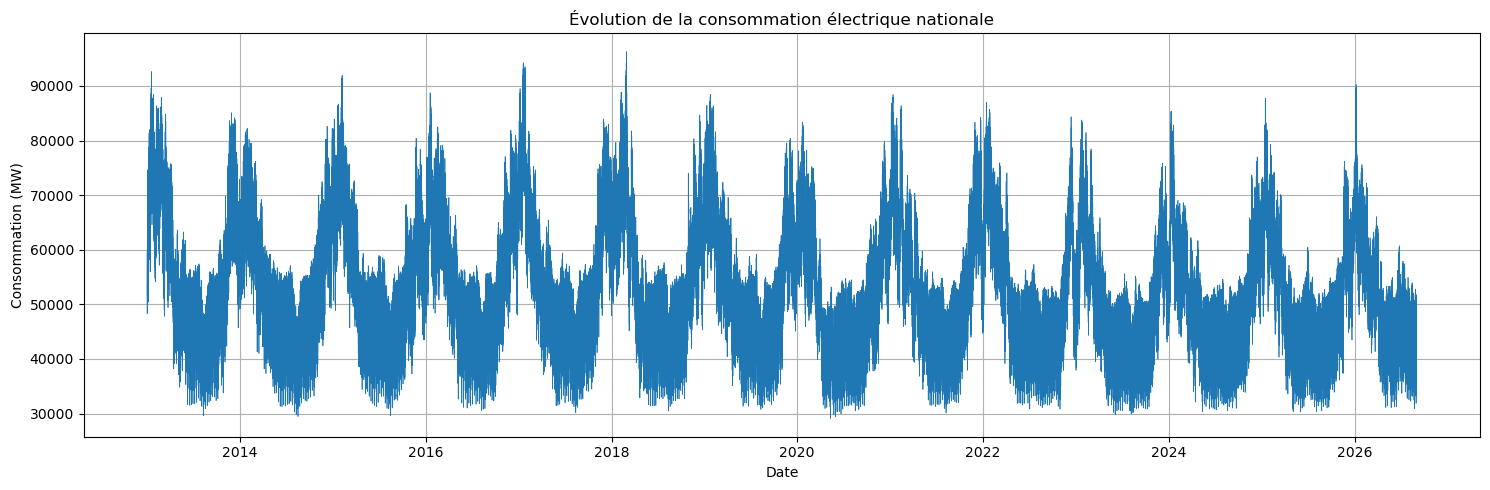

In [21]:
# Statistiques descriptives de la consommation nationale
display(df_national["Consommation (MW)"].describe())

# Évolution de la consommation sur toute la période
plt.figure(figsize=(15, 5))
plt.plot(
    df_national.index,
    df_national["Consommation (MW)"],
    linewidth=0.5
)
plt.title("Évolution de la consommation électrique nationale")
plt.xlabel("Date")
plt.ylabel("Consommation (MW)")
plt.grid(True)
plt.tight_layout()
plt.show()

*Ce qu'on peut observer ici, c'est surtout des variations entre des fortes périodes de consommation et des périodes beaucoup plus faibles. Afin de vérifier cela nous allons observer la consommation par mois*

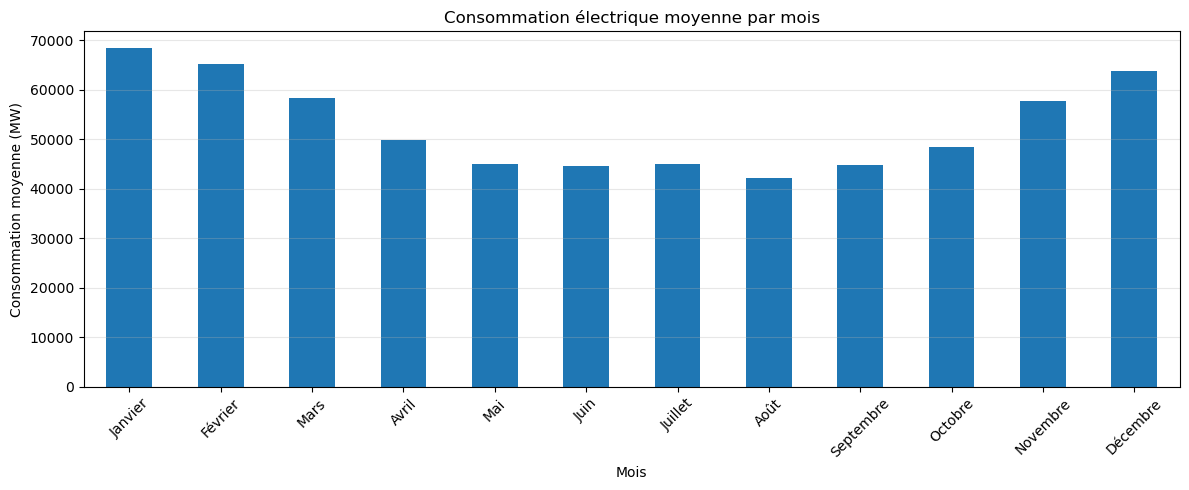

In [22]:
# Calcul de la consommation moyenne par mois
consommation_mensuelle = (
    df_national["Consommation (MW)"]
    .groupby(df_national.index.month)
    .mean()
)

# Associer les numéros de mois à leurs noms
noms_mois = [
    "Janvier", "Février", "Mars", "Avril",
    "Mai", "Juin", "Juillet", "Août",
    "Septembre", "Octobre", "Novembre", "Décembre"
]

consommation_mensuelle.index = noms_mois

# Visualisation
plt.figure(figsize=(12, 5))
consommation_mensuelle.plot(kind="bar")
plt.title("Consommation électrique moyenne par mois")
plt.xlabel("Mois")
plt.ylabel("Consommation moyenne (MW)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

*Cela confirme évidemment ce qu'on avait pu observer sur notre premier graphique, à savoir une saisonalité très importante. Maintenant analysons d'une année à une autre afin de savoir si on peut aussi observer une tendance au fil des ans*

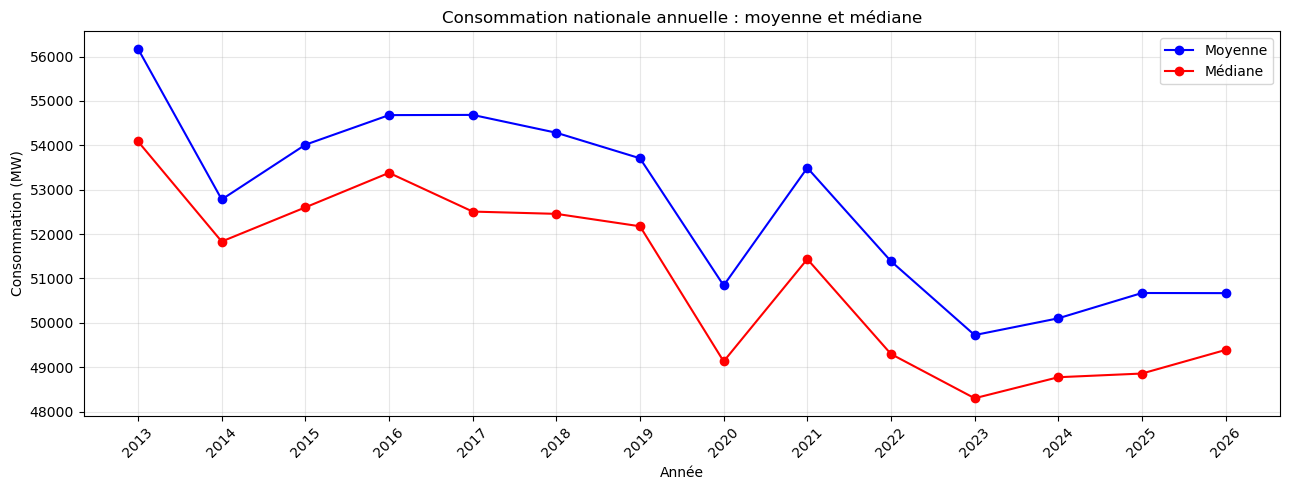

In [23]:

# Calcul des statistiques annuelles nationales
conso_annuelle = df_national["Consommation (MW)"].groupby(
    df_national.index.year
)

moyenne_annuelle = conso_annuelle.mean()
mediane_annuelle = conso_annuelle.median()

# Tracé
plt.figure(figsize=(13, 5))

plt.plot(
    moyenne_annuelle.index,
    moyenne_annuelle.values,
    color="blue",
    marker="o",
    label="Moyenne"
)

plt.plot(
    mediane_annuelle.index,
    mediane_annuelle.values,
    color="red",
    marker="o",
    label="Médiane"
)

plt.title("Consommation nationale annuelle : moyenne et médiane")
plt.xlabel("Année")
plt.ylabel("Consommation (MW)")
plt.xticks(moyenne_annuelle.index, rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


*On peut imaginer avec ce graphe que toutes les régions n'ont pas la même influence ou la même évolution, ce qui se sait d'ailleurs de manière intuitive, regardons donc en détail les consommations des régions*

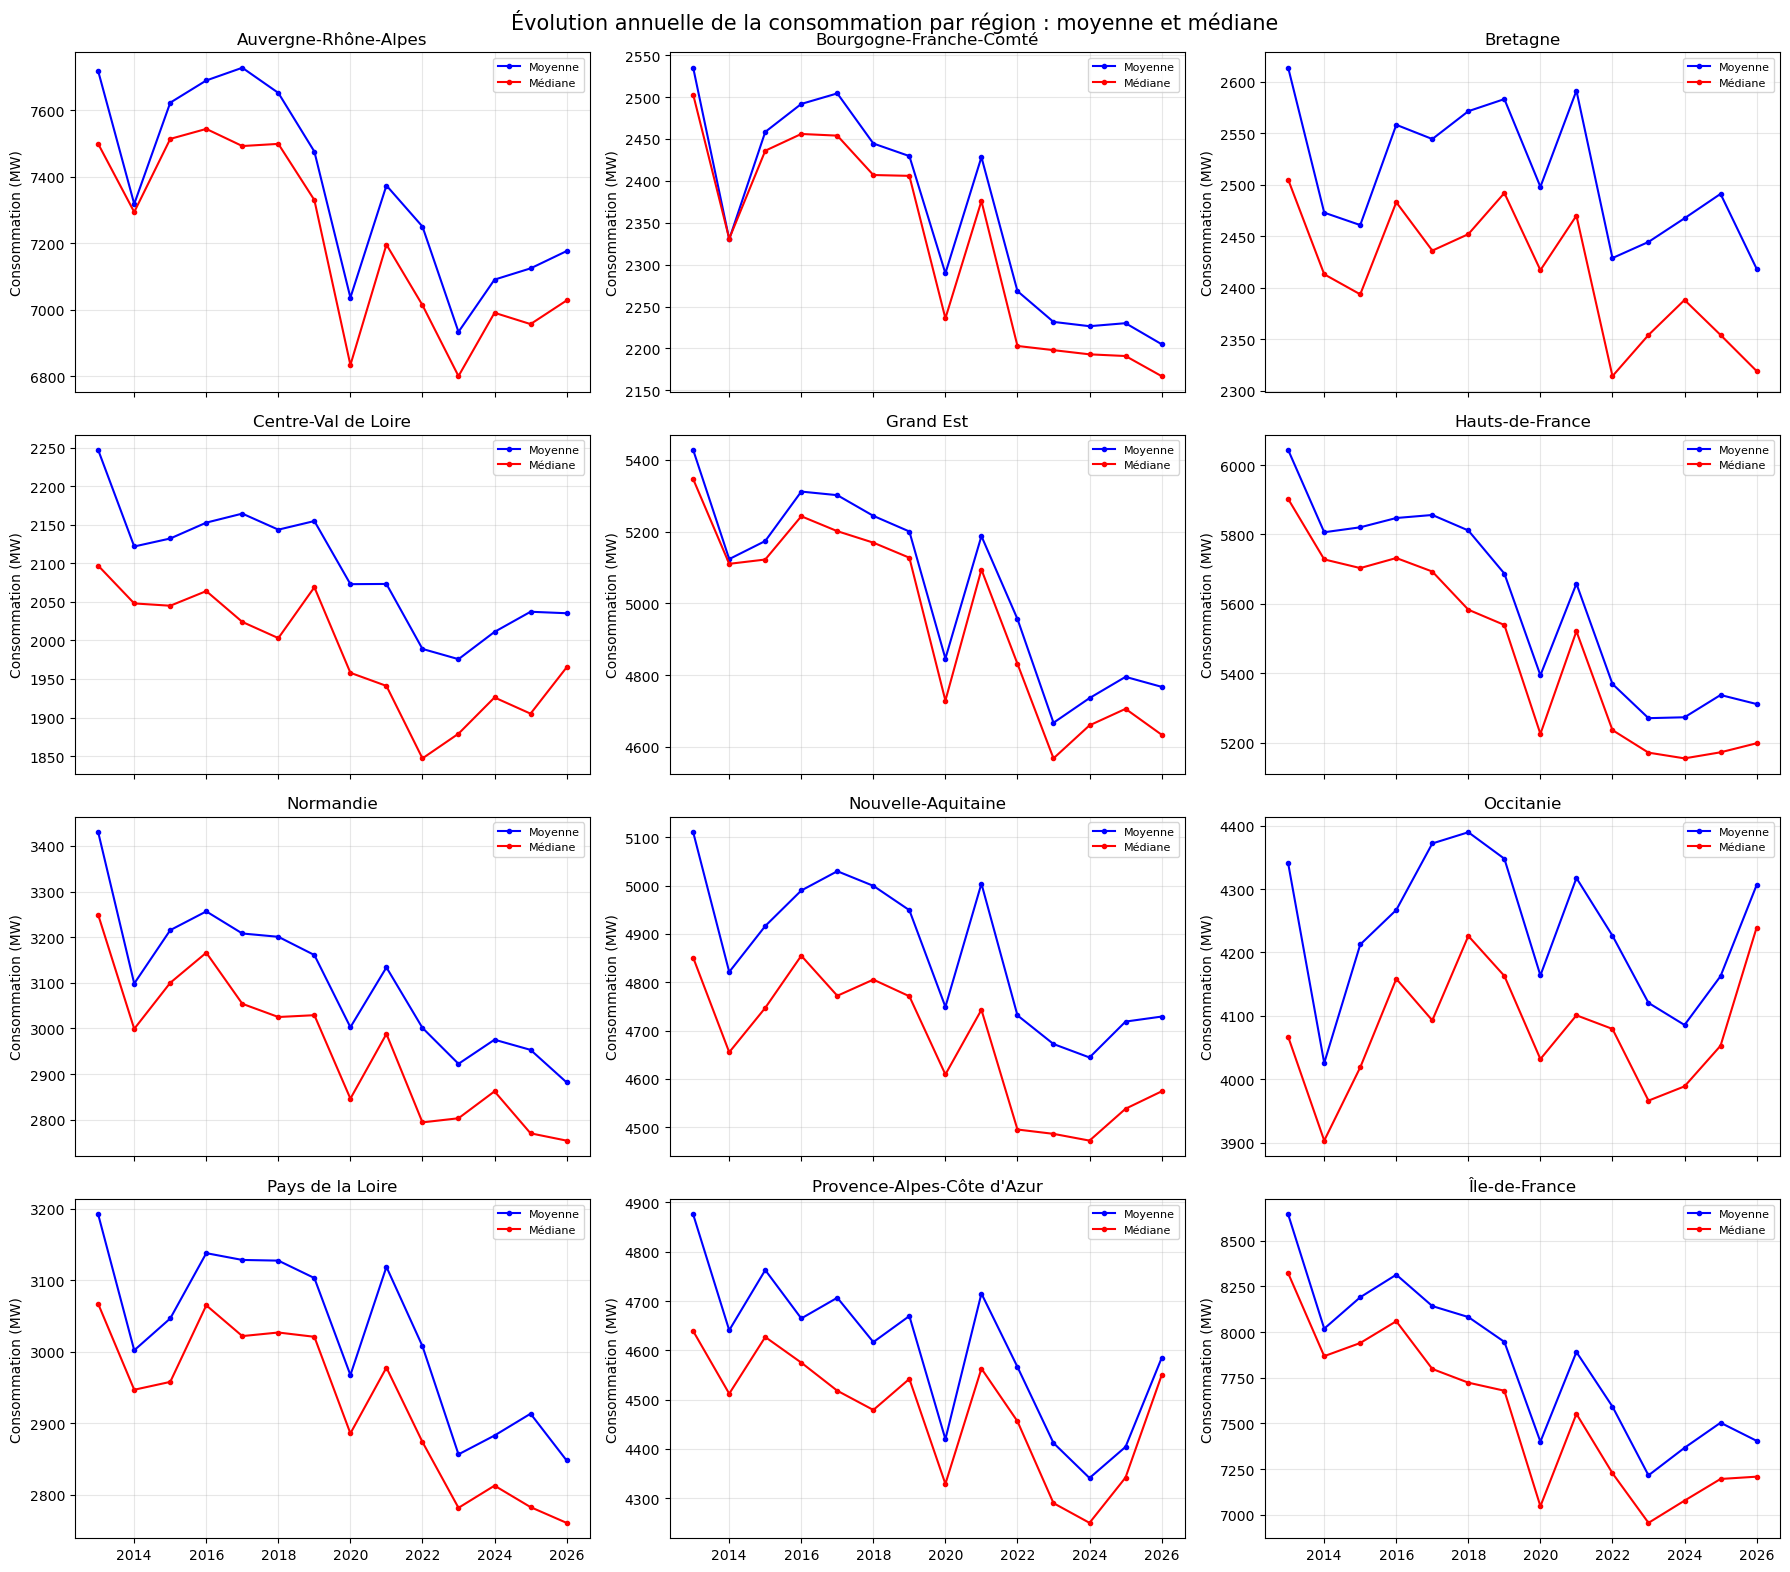

In [24]:

import math

# Calcul des moyennes et médianes annuelles par région
statistiques_regions = (
    df_travail
    .groupby([
        "Région",
        df_travail["Datetime"].dt.year
    ])["Consommation (MW)"]
    .agg(moyenne="mean", mediane="median")
    .reset_index()
)

# Identifier les régions et préparer la grille
regions = statistiques_regions["Région"].unique()
n_regions = len(regions)

n_colonnes = 3
n_lignes = math.ceil(n_regions / n_colonnes)

fig, axes = plt.subplots(
    n_lignes,
    n_colonnes,
    figsize=(18, 4 * n_lignes),
    sharex=True
)

axes = axes.flatten()

for i, region in enumerate(regions):
    ax = axes[i]

    donnees_region = (
        statistiques_regions[
            statistiques_regions["Région"] == region
        ]
        .sort_values("Datetime")
    )

    ax.plot(
        donnees_region["Datetime"],
        donnees_region["moyenne"],
        color="blue",
        marker="o",
        markersize=3,
        label="Moyenne"
    )

    ax.plot(
        donnees_region["Datetime"],
        donnees_region["mediane"],
        color="red",
        marker="o",
        markersize=3,
        label="Médiane"
    )

    ax.set_title(region)
    ax.set_ylabel("Consommation (MW)")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

# Supprimer les graphiques inutilisés
for j in range(n_regions, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Évolution annuelle de la consommation par région : moyenne et médiane",
    fontsize=15
)

plt.tight_layout()
plt.show()

*On garde toutefois en tête que les régions n'ont pas les mêmes population. L'objectif n'est pas la mais il faudrait normaliser le résultat si l'on voulait pousser l'analyse sur cet axe, passons maintenant à l'analyse sur 24h*

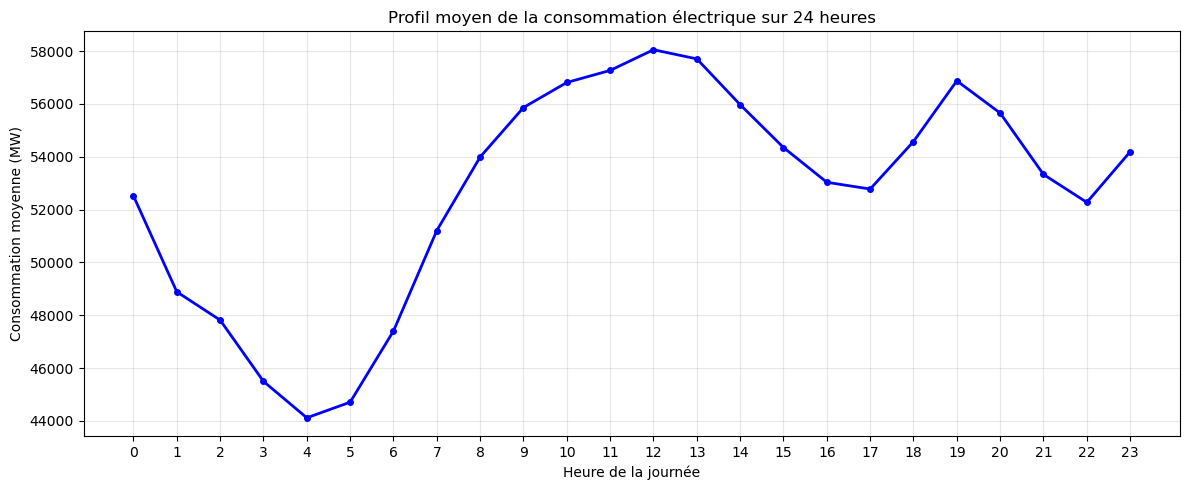

,Consommation moyenne (MW)
Datetime,
0,52520.0
1,48889.0
2,47818.0
3,45499.0
4,44119.0
5,44712.0
6,47407.0
7,51210.0
8,53993.0


In [25]:
# Calcul de la consommation moyenne selon l'heure de la journée

consommation_horaire = (
    df_national["Consommation (MW)"]
    .groupby(df_national.index.hour)
    .mean()
)

# Tracé du profil journalier moyen
plt.figure(figsize=(12, 5))

plt.plot(
    consommation_horaire.index,
    consommation_horaire.values,
    color="blue",
    marker="o",
    markersize=4,
    linewidth=2
)

plt.title("Profil moyen de la consommation électrique sur 24 heures")
plt.xlabel("Heure de la journée")
plt.ylabel("Consommation moyenne (MW)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Afficher les statistiques horaires
display(
    consommation_horaire.rename(
        "Consommation moyenne (MW)"
    ).to_frame().round(0)
)

*Ce résultat est cohérent avec les rythmes d'activité et les usages résidentiels, professionnels et industriels. Il s'agit toutefois d'une moyenne calculée sur toutes les saisons et toutes les années : les horaires et l'amplitude des pics peuvent différer en été et en hiver.*

*Maintenant on va comparer les jours ouvrés et les weekends afin de pouvoir plus tard avoir un modèle plus pertinent*

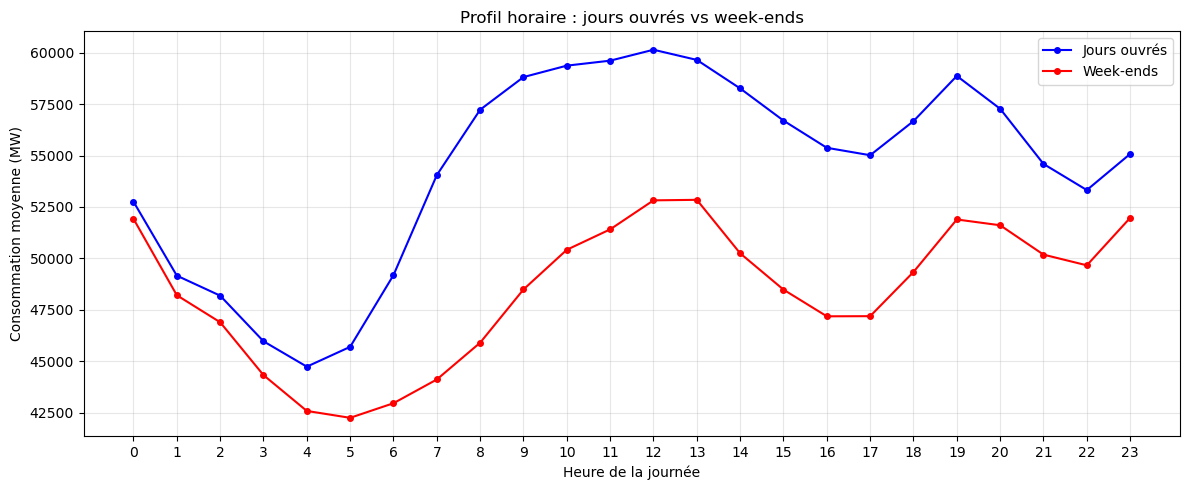

In [26]:

# Comparer les profils horaires des jours ouvrés et des week-ends

jours_semaine = df_national.index.dayofweek
heures = df_national.index.hour

conso_ouvrés = (
    df_national.loc[jours_semaine < 5, "Consommation (MW)"]
    .groupby(heures[jours_semaine < 5])
    .mean()
)

conso_weekends = (
    df_national.loc[jours_semaine >= 5, "Consommation (MW)"]
    .groupby(heures[jours_semaine >= 5])
    .mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    conso_ouvrés.index,
    conso_ouvrés.values,
    color="blue",
    marker="o",
    markersize=4,
    label="Jours ouvrés"
)

plt.plot(
    conso_weekends.index,
    conso_weekends.values,
    color="red",
    marker="o",
    markersize=4,
    label="Week-ends"
)

plt.title("Profil horaire : jours ouvrés vs week-ends")
plt.xlabel("Heure de la journée")
plt.ylabel("Consommation moyenne (MW)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

*- En semaine, on observe une forte hausse le matin, puis un pic principal autour de midi, à environ 60 000 MW, et un second pic vers 19 h.<br>- Le week-end, la hausse du matin est plus progressive et le maximum se situe également autour de midi, mais à environ 52 800 MW.
Les pics sont donc moins élevés le week-end en valeur absolue, mais leur forme diffère aussi. Pour déterminer si les pics sont réellement moins marqués, il faudrait comparer leur amplitude par rapport au niveau moyen de chaque type de journée.<br> on va donc visualiser la consommation moyenne pour chacun des sept jours. Cela permettra de vérifier si le samedi et le dimanche se distinguent des jours ouvrés.*

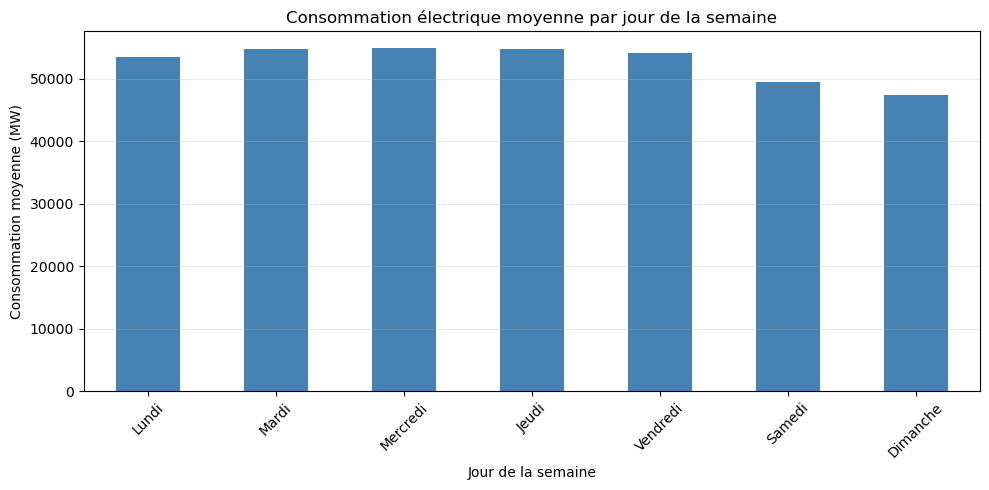

,Consommation moyenne (MW)
Lundi,53436.0
Mardi,54783.0
Mercredi,54879.0
Jeudi,54745.0
Vendredi,54191.0
Samedi,49538.0
Dimanche,47369.0


In [27]:
# Consommation moyenne par jour de la semaine

noms_jours = [
    "Lundi", "Mardi", "Mercredi", "Jeudi",
    "Vendredi", "Samedi", "Dimanche"
]

consommation_jour = (
    df_national["Consommation (MW)"]
    .groupby(df_national.index.dayofweek)
    .mean()
)

consommation_jour.index = noms_jours

plt.figure(figsize=(10, 5))
consommation_jour.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Consommation électrique moyenne par jour de la semaine")
plt.xlabel("Jour de la semaine")
plt.ylabel("Consommation moyenne (MW)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(
    consommation_jour.rename(
        "Consommation moyenne (MW)"
    ).to_frame().round(0)
)

*Maintenant que nous avons comparé avec différents aspects, on peut comparer sur les saisons*

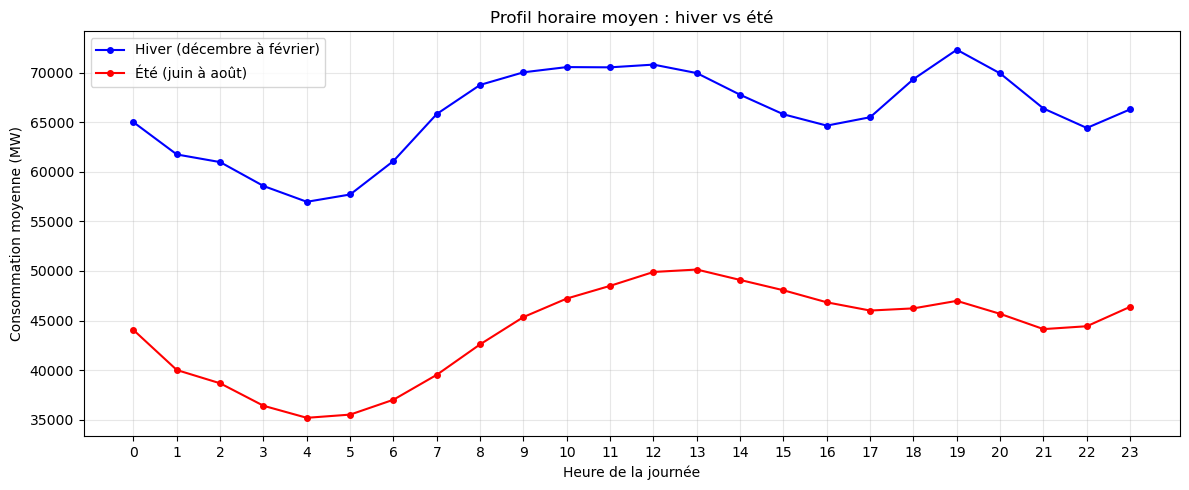

In [28]:

# Comparaison des profils horaires en hiver et en été

mois = df_national.index.month
heure = df_national.index.hour

# Hiver : décembre, janvier et février
conso_hiver = (
    df_national.loc[mois.isin([12, 1, 2]), "Consommation (MW)"]
    .groupby(heure[mois.isin([12, 1, 2])])
    .mean()
)

# Été : juin, juillet et août
conso_ete = (
    df_national.loc[mois.isin([6, 7, 8]), "Consommation (MW)"]
    .groupby(heure[mois.isin([6, 7, 8])])
    .mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    conso_hiver.index,
    conso_hiver.values,
    color="blue",
    marker="o",
    markersize=4,
    label="Hiver (décembre à février)"
)

plt.plot(
    conso_ete.index,
    conso_ete.values,
    color="red",
    marker="o",
    markersize=4,
    label="Été (juin à août)"
)

plt.title("Profil horaire moyen : hiver vs été")
plt.xlabel("Heure de la journée")
plt.ylabel("Consommation moyenne (MW)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Partie 2 Modélisation<br>**
*Étapes prévues<br>1. Construire une baseline à partir de l'historique de consommation et des variables temporelles.<br>
2. Ajouter les jours fériés et les vacances scolaires.<br>
3. Intégrer les données météorologiques pertinentes.<br>
4. Comparer les performances des différentes versions du modèle.<br>
5. Évaluer les prévisions sur une période future non utilisée pendant l'entraînement.<br>
6. Comparer les résultats à la prévision publiée par RTE.<br>
7. Préparer un pipeline de mise à jour à partir des données récentes.*

**Étape 1**<br>

**Entraînement de SVM et KNN**

In [29]:

# Reconstruire la série temporelle nationale

serie = df_national["Consommation (MW)"].copy()

# S'assurer que l'index est un DatetimeIndex
serie.index = pd.to_datetime(serie.index)

# Trier chronologiquement
serie = serie.sort_index()

print("Nombre de créneaux :", len(serie))
print("Début :", serie.index.min())
print("Fin :", serie.index.max())
print("Valeurs manquantes :", serie.isna().sum())

display(serie.head())


Nombre de créneaux : 239568
Début : 2013-01-01 00:00:00
Fin : 2026-08-31 23:30:00
Valeurs manquantes : 2


Datetime
2013-01-01 00:00:00        NaN
2013-01-01 00:30:00    59662.0
2013-01-01 01:00:00    57866.0
2013-01-01 01:30:00    57747.0
2013-01-01 02:00:00    57234.0
Name: Consommation (MW), dtype: float64

In [30]:
import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

# Série nationale de consommation
serie_ml = serie.sort_index().copy()

# Création des variables explicatives
donnees_ml = pd.DataFrame(index=serie_ml.index)

donnees_ml["Conso_reelle"] = serie_ml
donnees_ml["Conso_J_1"] = serie_ml.reindex(
    donnees_ml.index - pd.Timedelta(days=1)
).to_numpy()

donnees_ml["Conso_J_7"] = serie_ml.reindex(
    donnees_ml.index - pd.Timedelta(days=7)
).to_numpy()

donnees_ml["Heure"] = donnees_ml.index.hour
donnees_ml["Jour_semaine"] = donnees_ml.index.dayofweek
donnees_ml["Mois"] = donnees_ml.index.month
donnees_ml["Week_end"] = (
    donnees_ml.index.dayofweek >= 5
).astype(int)

donnees_ml = donnees_ml.dropna()

# Variables utilisées par les modèles
variables = [
    "Conso_J_1",
    "Conso_J_7",
    "Heure",
    "Jour_semaine",
    "Mois",
    "Week_end"
]

X = donnees_ml[variables]
y = donnees_ml["Conso_reelle"]

# Séparation chronologique : 80 % apprentissage, 20 % test
limite = int(len(donnees_ml) * 0.8)

X_train = X.iloc[:limite]
X_test = X.iloc[limite:]

y_train = y.iloc[:limite]
y_test = y.iloc[limite:]

print("Taille apprentissage :", len(X_train))
print("Taille test :", len(X_test))
print("Période de test :", X_test.index.min(), "à", X_test.index.max())

Taille apprentissage : 191382
Taille test : 47846
Période de test : 2023-12-09 03:30:00 à 2026-08-31 23:30:00


In [31]:
modele_arbre = DecisionTreeRegressor(
    max_depth=12,
    min_samples_leaf=20,
    random_state=42
)

modele_arbre.fit(X_train, y_train)

pred_arbre = modele_arbre.predict(X_test)

mae_arbre = mean_absolute_error(y_test, pred_arbre)
rmse_arbre = np.sqrt(mean_squared_error(y_test, pred_arbre))

print(f"MAE : {mae_arbre:.2f} MW")
print(f"RMSE : {rmse_arbre:.2f} MW")

MAE : 1618.51 MW
RMSE : 2355.82 MW


In [32]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Échantillon d'apprentissage réparti sur toute la période
n_echantillon = min(20000, len(X_train))

indices = np.linspace(
    0, len(X_train) - 1,
    n_echantillon,
    dtype=int
)

X_train_knn = X_train.iloc[indices]
y_train_knn = y_train.iloc[indices]

# Création et entraînement du modèle
modele_knn = make_pipeline(
    StandardScaler(),
    KNeighborsRegressor(n_neighbors=5, weights="distance")
)

modele_knn.fit(X_train_knn, y_train_knn)

# Prédictions sur la période de test
pred_knn = modele_knn.predict(X_test)

# Évaluation
mae_knn = mean_absolute_error(y_test, pred_knn)
rmse_knn = np.sqrt(mean_squared_error(y_test, pred_knn))

print(f"MAE KNN : {mae_knn:.2f} MW")
print(f"RMSE KNN : {rmse_knn:.2f} MW")

MAE KNN : 1704.32 MW
RMSE KNN : 2443.78 MW


In [33]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Échantillon d'apprentissage réparti dans le temps
n_echantillon_svr = min(5000, len(X_train))

indices_svr = np.linspace(
    0, len(X_train) - 1,
    n_echantillon_svr,
    dtype=int
)

X_train_svr = X_train.iloc[indices_svr]
y_train_svr = y_train.iloc[indices_svr]

# Création du modèle SVR
modele_svr = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", C=100, epsilon=100)
)

# Entraînement
modele_svr.fit(X_train_svr, y_train_svr)

# Prédictions
pred_svr = modele_svr.predict(X_test)

# Évaluation
mae_svr = mean_absolute_error(y_test, pred_svr)
rmse_svr = np.sqrt(mean_squared_error(y_test, pred_svr))

print(f"MAE SVR : {mae_svr:.2f} MW")
print(f"RMSE SVR : {rmse_svr:.2f} MW")

MAE SVR : 2351.84 MW
RMSE SVR : 3202.18 MW


In [34]:
resultats = pd.DataFrame([
    {
        "Modèle": "Arbre de décision",
        "MAE (MW)": mae_arbre,
        "RMSE (MW)": rmse_arbre
    },
    {
        "Modèle": "KNN (k=5)",
        "MAE (MW)": mae_knn,
        "RMSE (MW)": rmse_knn
    },
    {
        "Modèle": "SVR (SVM)",
        "MAE (MW)": mae_svr,
        "RMSE (MW)": rmse_svr
    }
])

# Trier les modèles par MAE croissante
resultats = resultats.sort_values(
    by="MAE (MW)"
).reset_index(drop=True)
display(resultats.round(2))

,Modèle,MAE (MW),RMSE (MW)
0,Arbre de décision,1618.51,2355.82
1,KNN (k=5),1704.32,2443.78
2,SVR (SVM),2351.84,3202.18


*On constate qu'ici le modèle le plus performant est l'arbre de décision, on va donc continuer avec ce modèle.<br> Il est cependant trop tôt pour dire que c'est le meilleur modèle en tout point, on va donc enrichir les données et tester les autres modèles plus tard aussi, on garde celui-ci provisoirement*

**Étape 2**

*On va ajouter les données via intégration de données météo*

In [35]:
%pip install openmeteo-requests requests-cache retry-requests

  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
Using cached attrs-26.1.0-py3-none-any.whl (67 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 873.8/873.8 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 631.1/631.1 kB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 13.7 MB/s eta 0:00:00a 0:00:01
Using cached typing_extensions-4.16.0-py3-none-any.whl (45 kB)
  Attempting uninstall: typing-extensions
    Found existing installation: typing_extensions 4.12.2
    Uninstalling typing_extensions-4.12.2:
      Successfully uninstalled typing_extensions-4.12.2━━━━━━━━━━━  3/14 [typing-extensions]
  Attempting uninstall: attrs━━━━━━━━━━━━━━━━━━━━━━━━━━━━  4/14 [qh3]xtensions]
    Found existing installation: attrs 24.3.0━━━━━━━━━━━━━━━━━  4/14 [qh3]
    Uninstalling attrs-24.3.0:━━━━━━━━━━━━━━━━━━━━━━━━━━━━  4/14 [qh3]
      Successfully uninstalled attrs-2

**Téléchargement des données**

In [36]:
import requests
import pandas as pd
import numpy as np
import time

# Points représentatifs des 12 régions métropolitaines
regions = {
    "Auvergne-Rhône-Alpes": (45.76, 4.84),
    "Bourgogne-Franche-Comté": (47.32, 5.04),
    "Bretagne": (48.11, -1.68),
    "Centre-Val de Loire": (47.90, 1.91),
    "Grand Est": (48.58, 7.75),
    "Hauts-de-France": (50.63, 3.06),
    "Île-de-France": (48.86, 2.35),
    "Normandie": (49.44, 1.10),
    "Nouvelle-Aquitaine": (44.84, -0.58),
    "Occitanie": (43.60, 1.44),
    "Pays de la Loire": (47.22, -1.55),
    "Provence-Alpes-Côte d'Azur": (43.30, 5.37)
}

# Coordonnées pour la requête groupée
latitudes = ",".join(str(c[0]) for c in regions.values())
longitudes = ",".join(str(c[1]) for c in regions.values())

variables_meteo = [
    "temperature_2m",
    "relative_humidity_2m",
    "apparent_temperature",
    "precipitation",
    "wind_speed_10m",
    "cloud_cover"
]

# Période couverte par la série de consommation
date_debut = serie.index.min().strftime("%Y-%m-%d")
date_fin = serie.index.max().strftime("%Y-%m-%d")

debut_annee = pd.Timestamp(date_debut).year
fin_annee = pd.Timestamp(date_fin).year

donnees_meteo = []

for annee in range(debut_annee, fin_annee + 1):
    debut = max(
        pd.Timestamp(f"{annee}-01-01"),
        pd.Timestamp(date_debut)
    )
    fin = min(
        pd.Timestamp(f"{annee}-12-31"),
        pd.Timestamp(date_fin)
    )

    print(f"Téléchargement météo : {annee}")

    params = {
        "latitude": latitudes,
        "longitude": longitudes,
        "start_date": debut.strftime("%Y-%m-%d"),
        "end_date": fin.strftime("%Y-%m-%d"),
        "hourly": ",".join(variables_meteo),
        "timezone": "Europe/Paris",
        "models": "era5"
    }

    reponse = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params=params,
        timeout=180
    )
    reponse.raise_for_status()
    contenu = reponse.json()

    # L'API peut renvoyer une liste de résultats
    # lorsque plusieurs coordonnées sont demandées.
    if isinstance(contenu, dict):
        contenu = [contenu]

    for resultat in contenu:
        df_meteo_region = pd.DataFrame(
            resultat["hourly"]
        )
        donnees_meteo.append(df_meteo_region)

    time.sleep(1)

# Regrouper les observations des différents points
meteo_tous_points = pd.concat(
    donnees_meteo,
    ignore_index=True
)

meteo_tous_points["time"] = pd.to_datetime(
    meteo_tous_points["time"]
)

# Moyenne des points météo pour chaque heure
meteo_horaire = (
    meteo_tous_points
    .groupby("time")[variables_meteo]
    .mean()
    .sort_index()
)

# Renommer les variables
meteo_horaire = meteo_horaire.rename(columns={
    "temperature_2m": "Temperature_moyenne",
    "relative_humidity_2m": "Humidite_moyenne",
    "apparent_temperature": "Temperature_ressentie",
    "precipitation": "Precipitations",
    "wind_speed_10m": "Vent",
    "cloud_cover": "Nebulosite"
})

print("Dimensions météo :", meteo_horaire.shape)
display(meteo_horaire.head())

Téléchargement météo : 2013
Téléchargement météo : 2014
Téléchargement météo : 2015
Téléchargement météo : 2016
Téléchargement météo : 2017


HTTPError: 429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=45.76%2C47.32%2C48.11%2C47.9%2C48.58%2C50.63%2C48.86%2C49.44%2C44.84%2C43.6%2C47.22%2C43.3&longitude=4.84%2C5.04%2C-1.68%2C1.91%2C7.75%2C3.06%2C2.35%2C1.1%2C-0.58%2C1.44%2C-1.55%2C5.37&start_date=2017-01-01&end_date=2017-12-31&hourly=temperature_2m%2Crelative_humidity_2m%2Capparent_temperature%2Cprecipitation%2Cwind_speed_10m%2Ccloud_cover&timezone=Europe%2FParis&models=era5

*trop d'appels d'un coup on va faire un appel complémentaire pour récupérer ce qui manque*

In [37]:
import requests
import pandas as pd
import time

session = requests.Session()
url = "https://archive-api.open-meteo.com/v1/archive"

# Repérer les années déjà téléchargées
annees_terminees = set()

for df_temp in donnees_meteo:
    if not df_temp.empty and "time" in df_temp.columns:
        annees_terminees.update(
            pd.to_datetime(df_temp["time"]).dt.year.unique()
        )

for annee in range(debut_annee, fin_annee + 1):

    if annee in annees_terminees:
        print(f"Année {annee} déjà téléchargée : ignorée")
        continue

    debut = max(
        pd.Timestamp(f"{annee}-01-01"),
        pd.Timestamp(date_debut)
    )
    fin = min(
        pd.Timestamp(f"{annee}-12-31"),
        pd.Timestamp(date_fin)
    )

    params = {
        "latitude": latitudes,
        "longitude": longitudes,
        "start_date": debut.strftime("%Y-%m-%d"),
        "end_date": fin.strftime("%Y-%m-%d"),
        "hourly": ",".join(variables_meteo),
        "timezone": "Europe/Paris",
        "models": "era5"
    }

    succes = False

    for tentative in range(5):
        try:
            print(
                f"Téléchargement {annee} "
                f"(tentative {tentative + 1}/5)"
            )

            reponse = session.get(
                url,
                params=params,
                timeout=180
            )

            if reponse.status_code == 429:
                attente = min(60 * (tentative + 1), 300)
                print(f"Limite API atteinte. Pause de {attente} s.")
                time.sleep(attente)
                continue

            reponse.raise_for_status()
            contenu = reponse.json()

            if isinstance(contenu, dict):
                contenu = [contenu]

            # Vérifier que les 12 points ont été reçus
            if len(contenu) != len(regions):
                raise ValueError(
                    f"{len(contenu)} résultats reçus "
                    f"au lieu de {len(regions)}."
                )

            # Ajouter les données seulement si tout est reçu
            for resultat in contenu:
                donnees_meteo.append(
                    pd.DataFrame(resultat["hourly"])
                )

            succes = True
            annees_terminees.add(annee)
            print(f"Année {annee} téléchargée avec succès.")
            time.sleep(10)
            break

        except (requests.RequestException, ValueError) as erreur:
            print("Erreur :", erreur)

            if tentative < 4:
                time.sleep(min(30 * (tentative + 1), 120))

    if not succes:
        print(
            f"Arrêt en {annee}. Relance cette cellule plus tard "
            "pour reprendre les années manquantes."
        )
        break

print("Années téléchargées :", sorted(annees_terminees))

Année 2013 déjà téléchargée : ignorée
Année 2014 déjà téléchargée : ignorée
Année 2015 déjà téléchargée : ignorée
Année 2016 déjà téléchargée : ignorée
Téléchargement 2017 (tentative 1/5)
Année 2017 téléchargée avec succès.
Téléchargement 2018 (tentative 1/5)
Année 2018 téléchargée avec succès.
Téléchargement 2019 (tentative 1/5)
Année 2019 téléchargée avec succès.
Téléchargement 2020 (tentative 1/5)
Année 2020 téléchargée avec succès.
Téléchargement 2021 (tentative 1/5)
Année 2021 téléchargée avec succès.
Téléchargement 2022 (tentative 1/5)
Année 2022 téléchargée avec succès.
Téléchargement 2023 (tentative 1/5)
Limite API atteinte. Pause de 60 s.
Téléchargement 2023 (tentative 2/5)
Année 2023 téléchargée avec succès.
Téléchargement 2024 (tentative 1/5)
Année 2024 téléchargée avec succès.
Téléchargement 2025 (tentative 1/5)
Année 2025 téléchargée avec succès.
Téléchargement 2026 (tentative 1/5)
Année 2026 téléchargée avec succès.
Années téléchargées : [np.int32(2013), np.int32(2014), n

In [38]:
# Fusionner les données météo déjà récupérées
meteo_temp = pd.concat(
    donnees_meteo,
    ignore_index=True
)

# Enregistrer sur le disque
meteo_temp.to_csv(
    "meteo_points_deja_telecharges.csv",
    index=False
)

print("Sauvegarde effectuée :", meteo_temp.shape)

Sauvegarde effectuée : (1437408, 7)


In [39]:
meteo_temp = pd.read_csv("meteo_points_deja_telecharges.csv")

meteo_temp["time"] = pd.to_datetime(meteo_temp["time"])

print("Dimensions des données météo :", meteo_temp.shape)
print("Période couverte :",
      meteo_temp["time"].min(),
      "à",
      meteo_temp["time"].max())

display(meteo_temp.head())

Dimensions des données météo : (1437408, 7)
Période couverte : 2013-01-01 00:00:00 à 2026-08-31 23:00:00


,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,cloud_cover
0,2013-01-01 00:00:00,8.0,67,3.3,0.0,20.7,80
1,2013-01-01 01:00:00,8.0,70,3.4,0.0,20.9,95
2,2013-01-01 02:00:00,8.2,74,3.5,0.0,22.4,98
3,2013-01-01 03:00:00,8.3,76,3.6,0.0,23.1,99
4,2013-01-01 04:00:00,8.8,77,4.2,0.0,23.1,100


*Étape 2 — Construire la météo nationale horaire<br>
On calcule la moyenne des 12 points météo pour chaque heure. C'est une première approximation de la météo nationale, pas une moyenne pondérée par la population.*

In [40]:
variables_meteo = [
    "temperature_2m",
    "relative_humidity_2m",
    "apparent_temperature",
    "precipitation",
    "wind_speed_10m",
    "cloud_cover"
]

meteo_horaire = (
    meteo_temp
    .groupby("time")[variables_meteo]
    .mean()
    .sort_index()
)

meteo_horaire = meteo_horaire.rename(columns={
    "temperature_2m": "Temperature_moyenne",
    "relative_humidity_2m": "Humidite_moyenne",
    "apparent_temperature": "Temperature_ressentie",
    "precipitation": "Precipitations",
    "wind_speed_10m": "Vent",
    "cloud_cover": "Nebulosite"
})

print("Dimensions météo horaire :", meteo_horaire.shape)
display(meteo_horaire.head())

Dimensions météo horaire : (119784, 6)


,Temperature_moyenne,Humidite_moyenne,Temperature_ressentie,Precipitations,Vent,Nebulosite
time,,,,,,
2013-01-01 00:00:00,8.333333,83.666667,4.466667,0.641667,19.633333,92.333333
2013-01-01 01:00:00,8.133333,85.250000,4.425000,0.600000,18.491667,96.083333
2013-01-01 02:00:00,8.108333,86.000000,4.500000,0.433333,18.091667,96.250000
2013-01-01 03:00:00,8.091667,86.583333,4.533333,0.341667,17.783333,94.833333
2013-01-01 04:00:00,8.108333,87.083333,4.608333,0.333333,17.458333,88.750000


*Vérifions maintenant que la météo couvre bien la consommation, puis on fusionne*

In [41]:
print("Début consommation :", serie.index.min())
print("Fin consommation   :", serie.index.max())

print("Début météo :", meteo_horaire.index.min())
print("Fin météo   :", meteo_horaire.index.max())

debut_commun = max(serie.index.min(), meteo_horaire.index.min())
fin_commun = min(serie.index.max(), meteo_horaire.index.max())

print("Période commune :", debut_commun, "à", fin_commun)

Début consommation : 2013-01-01 00:00:00
Fin consommation   : 2026-08-31 23:30:00
Début météo : 2013-01-01 00:00:00
Fin météo   : 2026-08-31 23:00:00
Période commune : 2013-01-01 00:00:00 à 2026-08-31 23:00:00


In [42]:
# Construire un index commun aux deux séries
index_commun = meteo_horaire.index.union(serie.index).sort_values()

# Interpoler la météo sur les créneaux de 30 minutes
meteo_30min = (
    meteo_horaire
    .reindex(index_commun)
    .interpolate(method="time")
    .reindex(serie.index)
)

# Fusionner avec la consommation nationale
donnees_avec_meteo = pd.concat([
    serie.rename("Conso_reelle"),
    meteo_30min
], axis=1)

print("Dimensions finales :", donnees_avec_meteo.shape)
print("\nValeurs manquantes :")
display(donnees_avec_meteo.isna().sum().to_frame("Valeurs manquantes"))

display(donnees_avec_meteo.head())

Dimensions finales : (239568, 7)

Valeurs manquantes :


,Valeurs manquantes
Conso_reelle,2
Temperature_moyenne,0
Humidite_moyenne,0
Temperature_ressentie,0
Precipitations,0
Vent,0
Nebulosite,0


,Conso_reelle,Temperature_moyenne,Humidite_moyenne,Temperature_ressentie,Precipitations,Vent,Nebulosite
Datetime,,,,,,,
2013-01-01 00:00:00,NaN,8.333333,83.666667,4.466667,0.641667,19.633333,92.333333
2013-01-01 00:30:00,59662.0,8.233333,84.458333,4.445833,0.620833,19.062500,94.208333
2013-01-01 01:00:00,57866.0,8.133333,85.250000,4.425000,0.600000,18.491667,96.083333
2013-01-01 01:30:00,57747.0,8.120833,85.625000,4.462500,0.516667,18.291667,96.166667
2013-01-01 02:00:00,57234.0,8.108333,86.000000,4.500000,0.433333,18.091667,96.250000


*On va maintenant pouvoir entraîner un nouvel arbre avec ces données en plus pour voir si cela nous permet d'obtenir des résultats plus cohérents*

In [43]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Préparer les données en excluant les 2 consommations manquantes
donnees_test_meteo = donnees_avec_meteo.dropna().copy()

# Variables temporelles
donnees_test_meteo["Heure"] = donnees_test_meteo.index.hour
donnees_test_meteo["Jour_semaine"] = donnees_test_meteo.index.dayofweek
donnees_test_meteo["Mois"] = donnees_test_meteo.index.month
donnees_test_meteo["Jour_annee"] = donnees_test_meteo.index.dayofyear
donnees_test_meteo["Week_end"] = (
    donnees_test_meteo.index.dayofweek >= 5
).astype(int)

# Variables communes aux deux modèles
variables_base = [
    "Heure", "Jour_semaine", "Mois",
    "Jour_annee", "Week_end"
]

variables_meteo = [
    "Temperature_moyenne",
    "Humidite_moyenne",
    "Temperature_ressentie",
    "Precipitations",
    "Vent",
    "Nebulosite"
]

# Ajouter les consommations passées
for decalage, nom in [
    (1, "Conso_J_1"),
    (2, "Conso_J_2"),
    (7, "Conso_J_7"),
    (14, "Conso_J_14")
]:
    donnees_test_meteo[nom] = serie.reindex(
        donnees_test_meteo.index - pd.Timedelta(days=decalage)
    ).to_numpy()

donnees_test_meteo = donnees_test_meteo.dropna()

variables_communes = [
    "Conso_J_1", "Conso_J_2",
    "Conso_J_7", "Conso_J_14"
] + variables_base

variables_avec_meteo = variables_communes + variables_meteo

# Cible
y = donnees_test_meteo["Conso_reelle"]

# Même période pour les deux modèles
limite = int(len(donnees_test_meteo) * 0.8)

X_train_base = donnees_test_meteo[variables_communes].iloc[:limite]
X_test_base = donnees_test_meteo[variables_communes].iloc[limite:]

X_train_meteo = donnees_test_meteo[variables_avec_meteo].iloc[:limite]
X_test_meteo = donnees_test_meteo[variables_avec_meteo].iloc[limite:]

y_train = y.iloc[:limite]
y_test = y.iloc[limite:]

# Arbre sans météo
arbre_base = DecisionTreeRegressor(
    max_depth=12,
    min_samples_leaf=20,
    random_state=42
)
arbre_base.fit(X_train_base, y_train)
pred_base = arbre_base.predict(X_test_base)

# Arbre avec météo
arbre_meteo = DecisionTreeRegressor(
    max_depth=12,
    min_samples_leaf=20,
    random_state=42
)
arbre_meteo.fit(X_train_meteo, y_train)
pred_meteo = arbre_meteo.predict(X_test_meteo)

# Résultats
comparaison_meteo = pd.DataFrame([
    {
        "Modèle": "Arbre sans météo",
        "MAE (MW)": mean_absolute_error(y_test, pred_base),
        "RMSE (MW)": np.sqrt(mean_squared_error(y_test, pred_base))
    },
    {
        "Modèle": "Arbre avec météo",
        "MAE (MW)": mean_absolute_error(y_test, pred_meteo),
        "RMSE (MW)": np.sqrt(mean_squared_error(y_test, pred_meteo))
    }
])

display(comparaison_meteo.round(2))

,Modèle,MAE (MW),RMSE (MW)
0,Arbre sans météo,1622.04,2365.31
1,Arbre avec météo,1470.69,2118.82


*La météo est donc source d'information puisqu'elle améliore notre modèle<br>L’ajout de variables météorologiques améliore les performances de l’arbre de décision. La MAE passe de 1 622,04 MW à 1 470,69 MW, soit une diminution d’environ 9,33 %. La RMSE diminue quant à elle de 2 365,31 MW à 2 118,82 MW, soit une réduction d’environ 10,42 %.<br>
Ces résultats suggèrent que les conditions météorologiques apportent une information complémentaire aux variables temporelles et aux consommations passées. La température, notamment, peut contribuer à expliquer les variations de la demande électrique liées aux besoins de chauffage ou de climatisation.<br>
Cette amélioration reste à confirmer sur d’autres périodes de test. De plus, l’utilisation d’une météo historique réanalysée ne reproduit pas encore les conditions réelles d’une prévision opérationnelle à J+1, qui nécessiterait des prévisions météorologiques disponibles au moment de l’estimation.<br>On va maintenant ajouter les jours fériés pour voir si on peut aussi rajouter de l'information comme ça.*

In [45]:
url_jours_feries = (
    "https://etalab.github.io/"
    "jours-feries-france-data/json/metropole.json"
)

# Lire le JSON sous forme de dictionnaire : date -> nom du jour férié
jours_feries_dict = pd.read_json(
    url_jours_feries,
    typ="series"
)

# Construire explicitement le DataFrame avec un index de dates
jours_feries = pd.DataFrame({
    "Nom": jours_feries_dict.values
}, index=pd.to_datetime(jours_feries_dict.index))

jours_feries.index = jours_feries.index.normalize()
jours_feries.index.name = "Date"

print("Nombre de jours fériés :", len(jours_feries))
display(jours_feries.head())

Nombre de jours fériés : 285


,Nom
Date,
2031-01-01,1er janvier
2031-04-14,Lundi de Pâques
2031-05-01,1er mai
2031-05-08,8 mai
2031-05-22,Ascension


In [46]:
# Créer la liste des dates fériées
dates_feriees = jours_feries.index.normalize()

# Ajouter la variable au jeu de données avec météo
donnees_avec_meteo["Jour_ferie"] = (
    donnees_avec_meteo.index.normalize()
    .isin(dates_feriees)
    .astype(int)
)

print("Nombre de créneaux fériés :",
      donnees_avec_meteo["Jour_ferie"].sum())

display(
    donnees_avec_meteo[
        donnees_avec_meteo["Jour_ferie"] == 1
    ].head()
)

Nombre de créneaux fériés : 7248


,Conso_reelle,Temperature_moyenne,Humidite_moyenne,Temperature_ressentie,Precipitations,Vent,Nebulosite,Jour_ferie
Datetime,,,,,,,,
2013-01-01 00:00:00,NaN,8.333333,83.666667,4.466667,0.641667,19.633333,92.333333,1
2013-01-01 00:30:00,59662.0,8.233333,84.458333,4.445833,0.620833,19.062500,94.208333,1
2013-01-01 01:00:00,57866.0,8.133333,85.250000,4.425000,0.600000,18.491667,96.083333,1
2013-01-01 01:30:00,57747.0,8.120833,85.625000,4.462500,0.516667,18.291667,96.166667,1
2013-01-01 02:00:00,57234.0,8.108333,86.000000,4.500000,0.433333,18.091667,96.250000,1


In [47]:
# Ajouter la variable jour férié aux données déjà préparées
donnees_test_feries = donnees_test_meteo.copy()

donnees_test_feries["Jour_ferie"] = (
    donnees_test_feries.index.normalize()
    .isin(dates_feriees)
    .astype(int)
)

variables_avec_feries = variables_avec_meteo + ["Jour_ferie"]

# Même séparation chronologique
X_train_feries = donnees_test_feries[
    variables_avec_feries
].iloc[:limite]

X_test_feries = donnees_test_feries[
    variables_avec_feries
].iloc[limite:]

y_feries = donnees_test_feries["Conso_reelle"]
y_train_feries = y_feries.iloc[:limite]
y_test_feries = y_feries.iloc[limite:]

# Entraîner le modèle avec météo + jours fériés
arbre_feries = DecisionTreeRegressor(
    max_depth=12,
    min_samples_leaf=20,
    random_state=42
)

arbre_feries.fit(X_train_feries, y_train_feries)
pred_feries = arbre_feries.predict(X_test_feries)

# Comparaison
comparaison_feries = pd.DataFrame([
    {
        "Modèle": "Arbre avec météo",
        "MAE (MW)": mean_absolute_error(y_test_feries, pred_base),
        "RMSE (MW)": np.sqrt(
            mean_squared_error(y_test_feries, pred_base)
        )
    },
    {
        "Modèle": "Arbre avec météo + jours fériés",
        "MAE (MW)": mean_absolute_error(y_test_feries, pred_feries),
        "RMSE (MW)": np.sqrt(
            mean_squared_error(y_test_feries, pred_feries)
        )
    }
])

display(comparaison_feries.round(2))

,Modèle,MAE (MW),RMSE (MW)
0,Arbre avec météo,1622.04,2365.31
1,Arbre avec météo + jours fériés,1410.72,1968.93


*On constate que l'ajout des jours fériés apporte beaucoup d'information et on peut alors se demander si ça en apporte plus que la météo, ce que nous pouvons vérifier.*

In [48]:
mae_meteo = 1622.04
rmse_meteo = 2365.31

mae_feries = 1410.72
rmse_feries = 1968.93

variation_mae = mae_feries - mae_meteo
variation_rmse = rmse_feries - rmse_meteo

amelioration_mae = (mae_meteo - mae_feries) / mae_meteo * 100
amelioration_rmse = (rmse_meteo - rmse_feries) / rmse_meteo * 100

print(f"Variation du MAE : {variation_mae:.2f} MW")
print(f"Variation du RMSE : {variation_rmse:.2f} MW")
print(f"Amélioration du MAE : {amelioration_mae:.2f} %")
print(f"Amélioration du RMSE : {amelioration_rmse:.2f} %")

Variation du MAE : -211.32 MW
Variation du RMSE : -396.38 MW
Amélioration du MAE : 13.03 %
Amélioration du RMSE : 16.76 %


*La météo réduit le MAE d'environ 9,33 % par rapport au modèle sans météo. L'ajout des jours fériés réduit ensuite le MAE d'environ 4,08 % par rapport au modèle avec météo.<br>
La conclusion est donc plus nuancée : dans cette expérience, la météo apporte un gain plus important en pourcentage que les jours fériés pris isolément, même si les jours fériés améliorent encore nettement le résultat.*

**Intégration des vacances scolaires**

In [49]:
print("Dimensions :", donnees_test_feries.shape)
print("Période :", donnees_test_feries.index.min(), "→", donnees_test_feries.index.max())

display(
    donnees_test_feries[
        ["Conso_reelle", "Jour_ferie"]
    ].head()
)

Dimensions : (238890, 17)
Période : 2013-01-15 00:30:00 → 2026-08-31 23:30:00


,Conso_reelle,Jour_ferie
Datetime,,
2013-01-15 00:30:00,74138.0,0
2013-01-15 01:00:00,71345.0,0
2013-01-15 01:30:00,71322.0,0
2013-01-15 02:00:00,71087.0,0
2013-01-15 02:30:00,70678.0,0


In [50]:
url_vacances = (
    "https://data.education.gouv.fr/api/explore/v2.1/catalog/datasets/"
    "fr-en-calendrier-scolaire/records"
)

params = {
    "limit": 100,
    "offset": 0,
    "order_by": "start_date"
}

reponse = requests.get(url_vacances, params=params, timeout=30)
reponse.raise_for_status()

resultats = reponse.json()

print("Nombre d'enregistrements récupérés :", len(resultats["results"]))
display(pd.DataFrame(resultats["results"]).head())

Nombre d'enregistrements récupérés : 100


,description,population,start_date,end_date,location,zones,annee_scolaire
0,Vacances de la Toussaint,-,2009-10-25T23:00:00+00:00,2009-11-08T23:00:00+00:00,Corse,Corse,2009-2010
1,Vacances de Noël,-,2009-12-20T23:00:00+00:00,2010-01-03T23:00:00+00:00,Corse,Corse,2009-2010
2,Vacances d'Hiver,-,2010-02-21T23:00:00+00:00,2010-03-07T23:00:00+00:00,Corse,Corse,2009-2010
3,Vacances de Printemps,-,2010-04-25T22:00:00+00:00,2010-05-09T22:00:00+00:00,Corse,Corse,2009-2010
4,Vacances d'Été,Enseignants,2010-07-07T22:00:00+00:00,2010-09-07T22:00:00+00:00,Corse,Corse,2009-2010


In [52]:
url_vacances = (
    "https://data.education.gouv.fr/api/explore/v2.1/catalog/datasets/"
    "fr-en-calendrier-scolaire/records"
)

toutes_les_lignes = []
limite = 100
offset = 0

while True:
    params = {
        "limit": limite,
        "offset": offset,
        "order_by": "start_date"
    }

    reponse = requests.get(url_vacances, params=params, timeout=30)
    reponse.raise_for_status()

    resultat_page = reponse.json()["results"]

    if not resultat_page:
        break

    toutes_les_lignes.extend(resultat_page)
    offset += len(resultat_page)

    if len(resultat_page) < limite:
        break

vacances = pd.DataFrame(toutes_les_lignes)

print("Nombre total d'enregistrements :", len(vacances))
print("\nZones disponibles :")
print(vacances["zones"].value_counts(dropna=False))

display(vacances.head())

Nombre total d'enregistrements : 2587

Zones disponibles :
zones
Zone B                      840
Zone A                      600
Zone C                      375
Polynésie                   122
Corse                       115
Guadeloupe                   96
Mayotte                      72
Martinique                   68
Guyane                       68
Saint Pierre et Miquelon     66
Réunion                      59
Wallis et Futuna             53
Nouvelle Calédonie           53
Name: count, dtype: int64


,description,population,start_date,end_date,location,zones,annee_scolaire
0,Vacances de la Toussaint,-,2009-10-25T23:00:00+00:00,2009-11-08T23:00:00+00:00,Corse,Corse,2009-2010
1,Vacances de Noël,-,2009-12-20T23:00:00+00:00,2010-01-03T23:00:00+00:00,Corse,Corse,2009-2010
2,Vacances d'Hiver,-,2010-02-21T23:00:00+00:00,2010-03-07T23:00:00+00:00,Corse,Corse,2009-2010
3,Vacances de Printemps,-,2010-04-25T22:00:00+00:00,2010-05-09T22:00:00+00:00,Corse,Corse,2009-2010
4,Vacances d'Été,Enseignants,2010-07-07T22:00:00+00:00,2010-09-07T22:00:00+00:00,Corse,Corse,2009-2010


In [53]:
vacances["start_date"] = pd.to_datetime(
    vacances["start_date"], utc=True
).dt.tz_convert(None)

vacances["end_date"] = pd.to_datetime(
    vacances["end_date"], utc=True
).dt.tz_convert(None)

print("Début du calendrier :", vacances["start_date"].min())
print("Fin du calendrier :", vacances["end_date"].max())

display(
    vacances[
        ["description", "start_date", "end_date",
         "location", "zones", "annee_scolaire"]
    ].tail(10)
)

Début du calendrier : 2009-10-25 23:00:00
Fin du calendrier : 2029-07-06 22:00:00


,description,start_date,end_date,location,zones,annee_scolaire
2577,Vacances de Noël,2028-12-08 23:00:00,2029-01-07 23:00:00,Mayotte,Mayotte,2028-2029
2578,Vacances de Noël,2028-12-15 23:00:00,2029-01-14 23:00:00,Polynésie,Polynésie,2028-2029
2579,Vacances de Février,2029-02-16 23:00:00,2029-03-05 23:00:00,Polynésie,Polynésie,2028-2029
2580,Vacances de Carnaval,2029-02-16 23:00:00,2029-03-04 23:00:00,Mayotte,Mayotte,2028-2029
2581,Vacances de Pâques,2029-04-06 22:00:00,2029-04-15 22:00:00,Polynésie,Polynésie,2028-2029
2582,Vacances de Printemps,2029-04-27 22:00:00,2029-05-13 22:00:00,Mayotte,Mayotte,2028-2029
2583,Vacances de Mai,2029-05-18 22:00:00,2029-05-27 22:00:00,Polynésie,Polynésie,2028-2029
2584,Début des Grandes Vacances,2029-07-05 22:00:00,2029-07-05 22:00:00,Polynésie,Polynésie,2028-2029
2585,Début des Grandes Vacances,2029-07-06 22:00:00,2029-07-06 22:00:00,Polynésie,Polynésie,2028-2029
2586,Début des Vacances d'Été,2029-07-06 22:00:00,2029-07-06 22:00:00,Mayotte,Mayotte,2028-2029


*les données incluent aussi Mayotte, la Corse et la Polynésie. Pour notre modèle de consommation métropolitaine, nous allons sélectionner uniquement les zones A, B et C.*

In [54]:
# Conserver uniquement les zones scolaires métropolitaines A, B et C
zones_metropole = ["Zone A", "Zone B", "Zone C", "A", "B", "C"]

vacances_abc = vacances[
    vacances["zones"].astype(str).str.strip().isin(zones_metropole)
].copy()

print("Nombre d'enregistrements pour les zones A, B et C :",
      len(vacances_abc))

print("\nValeurs de la colonne zones :")
print(vacances_abc["zones"].value_counts())

display(
    vacances_abc[
        ["description", "start_date", "end_date",
         "location", "zones", "annee_scolaire"]
    ].head(10)
)

Nombre d'enregistrements pour les zones A, B et C : 1815

Valeurs de la colonne zones :
zones
Zone B    840
Zone A    600
Zone C    375
Name: count, dtype: int64


,description,start_date,end_date,location,zones,annee_scolaire
51,Vacances de la Toussaint,2017-10-20 22:00:00,2017-11-05 23:00:00,Bordeaux,Zone A,2017-2018
52,Vacances de la Toussaint,2017-10-20 22:00:00,2017-11-05 23:00:00,Poitiers,Zone A,2017-2018
53,Vacances de la Toussaint,2017-10-20 22:00:00,2017-11-05 23:00:00,Amiens,Zone B,2017-2018
54,Vacances de la Toussaint,2017-10-20 22:00:00,2017-11-05 23:00:00,Reims,Zone B,2017-2018
55,Vacances de la Toussaint,2017-10-20 22:00:00,2017-11-05 23:00:00,Toulouse,Zone C,2017-2018
56,Vacances de la Toussaint,2017-10-20 22:00:00,2017-11-05 23:00:00,Besançon,Zone A,2017-2018
57,Vacances de la Toussaint,2017-10-20 22:00:00,2017-11-05 23:00:00,Dijon,Zone A,2017-2018
58,Vacances de la Toussaint,2017-10-20 22:00:00,2017-11-05 23:00:00,Caen,Zone B,2017-2018
59,Vacances de la Toussaint,2017-10-20 22:00:00,2017-11-05 23:00:00,Nice,Zone B,2017-2018
60,Vacances de la Toussaint,2017-10-20 22:00:00,2017-11-05 23:00:00,Orléans-Tours,Zone B,2017-2018


In [55]:
# Vérifier les zones présentes dans le calendrier
print(vacances["zones"].value_counts().head(20))

zones
Zone B                      840
Zone A                      600
Zone C                      375
Polynésie                   122
Corse                       115
Guadeloupe                   96
Mayotte                      72
Martinique                   68
Guyane                       68
Saint Pierre et Miquelon     66
Réunion                      59
Wallis et Futuna             53
Nouvelle Calédonie           53
Name: count, dtype: int64


In [57]:
# Garder les vacances des zones A, B et C
vacances_abc = vacances[
    vacances["zones"].astype(str).str.strip().isin(
        ["Zone A", "Zone B", "Zone C"]
    )
].copy()

# Créer les dates calendaires
vacances_abc["date_debut"] = vacances_abc["start_date"].dt.normalize()
vacances_abc["date_fin"] = vacances_abc["end_date"].dt.normalize()

# Ajouter les indicateurs au jeu de données
for zone in ["A", "B", "C"]:
    colonne = f"Vacances_{zone}"
    donnees_test_feries[colonne] = 0

    vacances_zone = vacances_abc[
        vacances_abc["zones"] == f"Zone {zone}"
    ]

    for _, ligne in vacances_zone.iterrows():
        masque = (
            (donnees_test_feries.index.normalize() >= ligne["date_debut"])
            & (donnees_test_feries.index.normalize() <= ligne["date_fin"])
        )

        donnees_test_feries.loc[masque, colonne] = 1

print("Nombre de créneaux identifiés comme vacances par zone :")
display(donnees_test_feries[
    ["Vacances_A", "Vacances_B", "Vacances_C"]
].sum())

print("\nExemple de données pendant février 2025 :")
display(
    donnees_test_feries.loc[
        "2025-02-01":"2025-02-28",
        ["Conso_reelle", "Jour_ferie",
         "Vacances_A", "Vacances_B", "Vacances_C"]
    ].head(20)
)

Nombre de créneaux identifiés comme vacances par zone :


Vacances_A    56925
Vacances_B    57069
Vacances_C    56973
dtype: int64


Exemple de données pendant février 2025 :


,Conso_reelle,Jour_ferie,Vacances_A,Vacances_B,Vacances_C
Datetime,,,,,
2025-02-01 00:00:00,65395.0,0,0,0,0
2025-02-01 00:30:00,64581.0,0,0,0,0
2025-02-01 01:00:00,62001.0,0,0,0,0
2025-02-01 01:30:00,61104.0,0,0,0,0
2025-02-01 02:00:00,60354.0,0,0,0,0
2025-02-01 02:30:00,59909.0,0,0,0,0
2025-02-01 03:00:00,58553.0,0,0,0,0
2025-02-01 03:30:00,57659.0,0,0,0,0
2025-02-01 04:00:00,56773.0,0,0,0,0


In [58]:
# Afficher les vacances scolaires autour de février 2025
display(
    vacances_abc.loc[
        vacances_abc["start_date"].between(
            "2025-01-01", "2025-03-31"
        ),
        [
            "description", "start_date", "end_date",
            "location", "zones", "annee_scolaire"
        ]
    ].sort_values(["zones", "start_date"])
)

,description,start_date,end_date,location,zones,annee_scolaire
1793,Vacances d'Hiver,2025-02-21 23:00:00,2025-03-09 23:00:00,Grenoble,Zone A,2024-2025
1794,Vacances d'Hiver,2025-02-21 23:00:00,2025-03-09 23:00:00,Poitiers,Zone A,2024-2025
1795,Vacances d'Hiver,2025-02-21 23:00:00,2025-03-09 23:00:00,Besançon,Zone A,2024-2025
1796,Vacances d'Hiver,2025-02-21 23:00:00,2025-03-09 23:00:00,Dijon,Zone A,2024-2025
1797,Vacances d'Hiver,2025-02-21 23:00:00,2025-03-09 23:00:00,Lyon,Zone A,2024-2025
1800,Vacances d'Hiver,2025-02-21 23:00:00,2025-03-09 23:00:00,Bordeaux,Zone A,2024-2025
1801,Vacances d'Hiver,2025-02-21 23:00:00,2025-03-09 23:00:00,Clermont-Ferrand,Zone A,2024-2025
1802,Vacances d'Hiver,2025-02-21 23:00:00,2025-03-09 23:00:00,Limoges,Zone A,2024-2025
1774,Vacances d'Hiver,2025-02-07 23:00:00,2025-02-23 23:00:00,Amiens,Zone B,2024-2025
1775,Vacances d'Hiver,2025-02-07 23:00:00,2025-02-23 23:00:00,Nancy-Metz,Zone B,2024-2025


In [59]:
# Reconvertir les dates brutes de l'API vers l'heure française
vacances["start_date"] = (
    pd.to_datetime(vacances["start_date"], utc=True)
    .dt.tz_convert("Europe/Paris")
)

vacances["end_date"] = (
    pd.to_datetime(vacances["end_date"], utc=True)
    .dt.tz_convert("Europe/Paris")
)

# Extraire la date locale, sans heure ni fuseau
vacances["date_debut"] = vacances["start_date"].dt.date
vacances["date_fin"] = vacances["end_date"].dt.date

vacances_abc = vacances[
    vacances["zones"].astype(str).str.strip().isin(
        ["Zone A", "Zone B", "Zone C"]
    )
].copy()

display(
    vacances_abc.loc[
        vacances_abc["description"].eq("Vacances d'Hiver")
        & vacances_abc["annee_scolaire"].eq("2024-2025"),
        ["description", "date_debut", "date_fin", "location", "zones"]
    ].drop_duplicates().sort_values(["zones", "date_debut"])
)

,description,date_debut,date_fin,location,zones
1793,Vacances d'Hiver,2025-02-22,2025-03-10,Grenoble,Zone A
1794,Vacances d'Hiver,2025-02-22,2025-03-10,Poitiers,Zone A
1795,Vacances d'Hiver,2025-02-22,2025-03-10,Besançon,Zone A
1796,Vacances d'Hiver,2025-02-22,2025-03-10,Dijon,Zone A
1797,Vacances d'Hiver,2025-02-22,2025-03-10,Lyon,Zone A
1800,Vacances d'Hiver,2025-02-22,2025-03-10,Bordeaux,Zone A
1801,Vacances d'Hiver,2025-02-22,2025-03-10,Clermont-Ferrand,Zone A
1802,Vacances d'Hiver,2025-02-22,2025-03-10,Limoges,Zone A
1774,Vacances d'Hiver,2025-02-08,2025-02-24,Amiens,Zone B
1775,Vacances d'Hiver,2025-02-08,2025-02-24,Nancy-Metz,Zone B


In [60]:
dates_index = pd.Index(donnees_test_feries.index.date)

for zone in ["A", "B", "C"]:
    colonne = f"Vacances_{zone}"
    indicateur = pd.Series(0, index=donnees_test_feries.index, dtype="int8")

    vacances_zone = vacances_abc[
        vacances_abc["zones"].astype(str).str.strip() == f"Zone {zone}"
    ]

    for _, ligne in vacances_zone.iterrows():
        masque = (
            (dates_index >= ligne["date_debut"])
            & (dates_index <= ligne["date_fin"])
        )
        indicateur.loc[masque] = 1

    donnees_test_feries[colonne] = indicateur

display(
    donnees_test_feries.loc[
        "2025-02-01":"2025-02-28",
        ["Vacances_A", "Vacances_B", "Vacances_C"]
    ].groupby(donnees_test_feries.loc["2025-02-01":"2025-02-28"].index.date)
    .first()
)

,Vacances_A,Vacances_B,Vacances_C
2025-02-01,0,0,0
2025-02-02,0,0,0
2025-02-03,0,0,0
2025-02-04,0,0,0
2025-02-05,0,0,0
2025-02-06,0,0,0
2025-02-07,0,0,0
2025-02-08,0,1,0
2025-02-09,0,1,0
2025-02-10,0,1,0


In [61]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Variables utilisées précédemment
variables_sans_meteo = variables_communes.copy()
variables_meteo = variables_avec_meteo.copy()

variables_meteo_feries = variables_meteo + ["Jour_ferie"]
variables_completes = variables_meteo_feries + [
    "Vacances_A",
    "Vacances_B",
    "Vacances_C"
]

# Vérifier que toutes les variables existent
for colonne in variables_completes:
    if colonne not in donnees_test_feries.columns:
        raise ValueError(f"Colonne manquante : {colonne}")

# Conserver uniquement les observations complètes
colonnes_utiles = list(dict.fromkeys(
    ["Conso_reelle"] + variables_completes
))

donnees_modelisation = (
    donnees_test_feries[colonnes_utiles]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .sort_index()
)

print("Nombre d'observations :", len(donnees_modelisation))
print("Période :", donnees_modelisation.index.min(),
      "→", donnees_modelisation.index.max())

Nombre d'observations : 238890
Période : 2013-01-15 00:30:00 → 2026-08-31 23:30:00


In [62]:
# Séparation chronologique commune
limite = int(len(donnees_modelisation) * 0.8)

train = donnees_modelisation.iloc[:limite]
test = donnees_modelisation.iloc[limite:]

y_train = train["Conso_reelle"]
y_test = test["Conso_reelle"]

modeles_variables = {
    "Arbre sans météo ni calendrier": variables_sans_meteo,
    "Arbre avec météo": variables_meteo,
    "Arbre avec météo + jours fériés": variables_meteo_feries,
    "Arbre avec météo + jours fériés + vacances": variables_completes
}

resultats = []
modeles_entraines = {}

for nom, variables in modeles_variables.items():
    arbre = DecisionTreeRegressor(
        max_depth=12,
        min_samples_leaf=20,
        random_state=42
    )

    arbre.fit(train[variables], y_train)
    predictions = arbre.predict(test[variables])

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    resultats.append({
        "Modèle": nom,
        "MAE (MW)": mae,
        "RMSE (MW)": rmse
    })

    modeles_entraines[nom] = arbre

comparaison_modeles = pd.DataFrame(resultats)

display(
    comparaison_modeles
    .sort_values("MAE (MW)")
    .round(2)
    .reset_index(drop=True)
)

,Modèle,MAE (MW),RMSE (MW)
0,Arbre avec météo + jours fériés,1410.72,1968.93
1,Arbre avec météo + jours fériés + vacances,1411.95,1971.52
2,Arbre avec météo,1470.69,2118.82
3,Arbre sans météo ni calendrier,1622.04,2365.31


Les jours fériés permettent donc de réduire le MAE de 59,97 MW supplémentaires par rapport au modèle avec météo. En revanche, les vacances scolaires augmentent le MAE de 1,23 MW et le RMSE de 2,59 MW par rapport au modèle avec météo et jours fériés.<br>
Cette différence est très faible. Elle ne signifie pas que les vacances scolaires n’ont aucune influence sur la consommation électrique, mais simplement que ces indicateurs n’améliorent pas les prédictions de cet arbre de décision dans ce test précis.<br>
3. Pourquoi les vacances scolaires n’améliorent-elles pas le résultat ?<br>
Plusieurs explications sont possibles :<br>
- Information déjà présente : le jour de la semaine, le mois et les retards de consommation peuvent déjà refléter une partie des changements liés aux vacances.<br>
- Effet hétérogène : les vacances ne se déroulent pas aux mêmes dates dans les zones A, B et C. L’effet sur la consommation nationale peut donc être diffus.<br>
- Limites de l’arbre : avec les paramètres actuels, l’arbre ne tire peut-être pas profit de ces variables supplémentaires.<br>
- Bruit du test : une variation aussi faible peut être liée à la période testée plutôt qu’à une différence réellement significative.
Testons avec un autre modèle pour voir ci le résultat peut être meilleur avec une autre approche

**Test avec Random Forest**

In [64]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Modèle Random Forest
foret = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=20,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

# Entraînement
foret.fit(
    train[variables_completes],
    y_train
)

# Prédictions sur la même période de test
predictions_foret = foret.predict(
    test[variables_completes]
)

# Évaluation
mae_foret = mean_absolute_error(
    y_test,
    predictions_foret
)

rmse_foret = np.sqrt(
    mean_squared_error(y_test, predictions_foret)
)

print(f"MAE Random Forest : {mae_foret:.2f} MW")
print(f"RMSE Random Forest : {rmse_foret:.2f} MW")

MAE Random Forest : 1238.47 MW
RMSE Random Forest : 1726.31 MW


*On peut voir qu'effectivement le random Forest est meilleur*

In [65]:
comparaison_foret = pd.DataFrame([
    {
        "Modèle": "Arbre de décision",
        "MAE (MW)": 1411.95,
        "RMSE (MW)": 1971.52
    },
    {
        "Modèle": "Random Forest",
        "MAE (MW)": mae_foret,
        "RMSE (MW)": rmse_foret
    }
])

display(
    comparaison_foret
    .sort_values("MAE (MW)")
    .round(2)
    .reset_index(drop=True)
)

,Modèle,MAE (MW),RMSE (MW)
0,Random Forest,1238.47,1726.31
1,Arbre de décision,1411.95,1971.52


In [69]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error

# KNN : les 5 voisins les plus proches
modele_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("modele", KNeighborsRegressor(
        n_neighbors=5,
        weights="distance",
        n_jobs=-1
    ))
])

# SVM : régression avec noyau RBF
modele_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("modele", SVR(
        kernel="rbf",
        C=10,
        epsilon=0.1
    ))
])

resultats = []

In [ ]:
# KNN
modele_knn.fit(train[variables_completes], y_train)
pred_knn = modele_knn.predict(test[variables_completes])

resultats.append({
    "Modèle": "KNN",
    "MAE (MW)": mean_absolute_error(y_test, pred_knn),
    "RMSE (MW)": np.sqrt(mean_squared_error(y_test, pred_knn))
})

In [ ]:
# SVM
modele_svm.fit(train[variables_completes], y_train)
pred_svm = modele_svm.predict(test[variables_completes])

resultats.append({
    "Modèle": "SVM (SVR)",
    "MAE (MW)": mean_absolute_error(y_test, pred_svm),
    "RMSE (MW)": np.sqrt(mean_squared_error(y_test, pred_svm))
})

display(pd.DataFrame(resultats).round(2))